### Configuración del controlador e inicio de sesión Spark

El conector JDBC de MySQL (Connector/J 9.7.0) se descarga la primera vez en `~/.miid4103/jars` (requiere internet) y lo reutilizan los demás notebooks.

In [1]:
import os
import sys

# En la máquina virtual ya está todo instalado
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
IN_CODESPACES = os.environ.get('CODESPACES') == 'true'

if IN_COLAB or IN_CODESPACES:
    %pip install -q pyspark==4.2.0 pandas==2.3.3 numpy==2.5.3 pyarrow==25.0.1 matplotlib==3.11.2 fg-data-profiling==4.20.0 scipy==1.18.1 seaborn==0.13.2

if IN_COLAB:
    # Spark 4 requiere Java 17 o superior
    !apt-get install -y -qq openjdk-21-jdk-headless > /dev/null
    os.environ['JAVA_HOME'] = '/usr/lib/jvm/java-21-openjdk-amd64'

ENVIRONMENT = 'colab' if IN_COLAB else 'codespaces' if IN_CODESPACES else 'local'
print(f'Entorno detectado: {ENVIRONMENT}')

from pyspark.sql import SparkSession
from pyspark.sql import functions
from pyspark.sql.types import StructType
from pyspark.sql.types import FloatType, StringType, IntegerType, DateType
from pyspark.sql.functions import udf, col, length, isnan, when, count
import pyspark.sql.functions as f
from datetime import datetime
from pyspark.sql import types as t

from data_profiling import ProfileReport

import matplotlib.pyplot as plt
import numpy as np

Entorno detectado: local


In [2]:
from pathlib import Path
import urllib.request

CONNECTOR_VERSION = '9.7.0'
CONNECTOR_URL = ('https://repo1.maven.org/maven2/com/mysql/mysql-connector-j/'
                 f'{CONNECTOR_VERSION}/mysql-connector-j-{CONNECTOR_VERSION}.jar')

def obtener_jar_mysql():
    env_path = os.environ.get('CONNECTOR_J_PATH', '')
    if env_path and Path(env_path).is_file():
        return Path(env_path)
    jar = Path.home() / '.miid4103' / 'jars' / f'mysql-connector-j-{CONNECTOR_VERSION}.jar'
    if not jar.exists():
        jar.parent.mkdir(parents=True, exist_ok=True)
        print(f'Descargando MySQL Connector/J {CONNECTOR_VERSION}...')
        parcial = jar.with_suffix('.part')
        urllib.request.urlretrieve(CONNECTOR_URL, parcial)
        parcial.replace(jar)
    return jar

MYSQL_JAR = obtener_jar_mysql()
MYSQL_JAR_URI = MYSQL_JAR.as_uri()
print(f'Conector JDBC: {MYSQL_JAR}')

Conector JDBC: C:\Users\astri\.miid4103\jars\mysql-connector-j-9.7.0.jar


In [3]:
os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable
# Necesario en Windows si Python está en C:\Program Files
import pyspark
os.environ.setdefault('SPARK_HOME', os.path.dirname(pyspark.__file__))
# Spark 4.2 en Windows requiere HADOOP_HOME
if os.name == 'nt' and 'HADOOP_HOME' not in os.environ:
    hadoop_home = Path.home() / '.miid4103' / 'hadoop'
    (hadoop_home / 'bin').mkdir(parents=True, exist_ok=True)
    (hadoop_home / 'bin' / 'winutils.exe').touch()
    os.environ['HADOOP_HOME'] = str(hadoop_home)

# En macOS con Java de Homebrew el kernel de Jupyter no siempre encuentra Java (error JAVA_GATEWAY_EXITED)
if 'JAVA_HOME' not in os.environ and os.path.exists('/usr/libexec/java_home'):
    import subprocess
    os.environ['JAVA_HOME'] = subprocess.run(['/usr/libexec/java_home'], capture_output=True, text=True).stdout.strip()

spark = (SparkSession.builder
         .master('local[*]')
         .appName('MIID4103-NB02')
         .config('spark.driver.host', '127.0.0.1')
         .config('spark.jars', MYSQL_JAR_URI)
         .config('spark.sql.execution.arrow.pyspark.enabled', 'true')
         .config('spark.sql.shuffle.partitions', '8')
         .config('spark.ui.enabled', 'false')
         .config('spark.ui.showConsoleProgress', 'false')
         .config('spark.sql.ansi.enabled', 'false')    # comportamiento de Spark 3.5
         .getOrCreate())
spark.sparkContext.setLogLevel('ERROR')

In [4]:
db_host = '157.253.236.120'
db_port = 8080
db_user = 'DB_202615_al_roa '.strip()
db_psswd = '202626538'

if not db_user or not db_psswd:
    raise ValueError('Complete db_user y db_psswd antes de continuar')
jdbc_opciones = 'useConfigs=maxPerformance&connectTimeout=10000&socketTimeout=600000'
db_connection_string = f'jdbc:mysql://{db_host}:{db_port}/RaSaTransaccional?{jdbc_opciones}'

# En Colab, suba los archivos a /content/
PATH = '/content/' if ENVIRONMENT == 'colab' else './'

OUT = Path('/content/salidas') if ENVIRONMENT == 'colab' else Path.home() / 'MIID4103' / 'salidas'
OUT.mkdir(parents=True, exist_ok=True)

# Conexión fuente de datos

In [5]:
def obtener_dataframe_de_bd(db_connection_string, sql, db_user, db_psswd):
    df_bd = spark.read.format('jdbc')\
        .option('url', db_connection_string) \
        .option('dbtable', sql) \
        .option('user', db_user) \
        .option('password', db_psswd) \
        .option('driver', 'com.mysql.cj.jdbc.Driver') \
        .load()
    return df_bd.cache()

In [6]:
# Conexión tabla Fuente Areas De servicio
sql_FuenteAreas = 'RaSaTransaccional.FuenteAreasDeServicio_Copia_E'

# Conexión tabla Fuente condiciones de pago
sql_FuenteCondicionesPago = 'RaSaTransaccional.FuenteCondicionesDePago_Copia_E'

# Conexión tabla Fuente planes beneficio
sql_FuentePlanesBeneficio = 'RaSaTransaccional.FuentePlanesBeneficio_Copia_E'

# Conexión tabla Fuente tipos beneficio
sql_FuenteTiposBeneficio = 'RaSaTransaccional.FuenteTiposBeneficio_Copia_E'


In [7]:
FuenteAreas = obtener_dataframe_de_bd(db_connection_string, sql_FuenteAreas, db_user, db_psswd)

FuenteCondicionesPago = obtener_dataframe_de_bd(db_connection_string, sql_FuenteCondicionesPago, db_user, db_psswd)

FuentePlanesBeneficio = obtener_dataframe_de_bd(db_connection_string, sql_FuentePlanesBeneficio, db_user, db_psswd)

FuenteTiposBeneficio = obtener_dataframe_de_bd(db_connection_string, sql_FuenteTiposBeneficio, db_user, db_psswd)

In [8]:
FuenteAreas.show(5) 
FuenteCondicionesPago.show(5)
FuentePlanesBeneficio.show(5)
FuenteTiposBeneficio.show(5)

+------------------+--------------------+-------------+-----------------+----------+------------+-----+--------+-----+
|IdAreaDeServicio_T|NombreAreaDeServicio|IdGeografia_T|          Condado|    Estado|PoblacionAct| Area|Densidad|Fecha|
+------------------+--------------------+-------------+-----------------+----------+------------+-----+--------+-----+
|         100622017|New Jersey - Medi...|        34005|Burlington County|New Jersey|    464269.0|805.0|   577.0| 2017|
|         101012018|New Jersey - Medi...|        34031|   Passaic County|New Jersey|    518117.0|185.0|  2801.0| 2018|
|          10132017|BlueOptions16842F...|        12031|     Duval County|   Florida|    999935.0|774.0|  1292.0| 2017|
|         101982018|New Jersey - Medi...|        34003|    Bergen County|New Jersey|    953819.0|234.0|  4076.0| 2018|
|         102012017|New Jersey - Medi...|        34021|    Mercer County|New Jersey|    385898.0|226.0|  1708.0| 2017|
+------------------+--------------------+-------

# Análisis de calidad de datos
La calidad de los datos consiste en validar la idoneidad de los datos analizando varias dimensiones:
- **Completitud**: datos que no existen o no se conocen (nulos, vacíos o marcadores como `NaN`).
- **Unicidad**: registros idénticos, o registros con la misma llave pero valores distintos.
- **Validez**: a nivel de formato y de sentido de los datos (dominios, rangos, signos).
- **Consistencia**: coherencia del dato al interior de una fila, entre filas de la misma fuente y entre fuentes.


In [9]:
def contar_vacios(df):
    """Nulos, textos vacíos y textos 'NaN' por columna."""
    total = df.count()
    resumen = []
    for c, tipo in df.dtypes:
        nulos = df.filter(col(c).isNull()).count()
        vacios = df.filter(f.trim(col(c)) == '').count() if tipo == 'string' else 0
        texto_nan = df.filter(f.lower(f.trim(col(c))) == 'nan').count() if tipo == 'string' else 0
        faltantes = nulos + vacios + texto_nan
        resumen.append((c, nulos, vacios, texto_nan, round(100 * faltantes / total, 2)))
    return spark.createDataFrame(resumen, ['columna', 'nulos', 'vacios', 'texto_NaN', 'pct_faltante'])

def cardinalidad(df):
    """Valores distintos por columna y su porcentaje sobre el total de filas."""
    total = df.count()
    resumen = [(c, df.select(c).distinct().count()) for c in df.columns]
    return spark.createDataFrame([(c, n, round(100 * n / total, 2)) for c, n in resumen],
                                 ['columna', 'distintos', 'pct_distintos'])

def registrar(res, nombre, df_casos, total):
    casos = df_casos.count()
    res.append((nombre, casos, total, round(casos / total * 100, 2) if total else None))

def mostrar_resultados(res):
    spark.createDataFrame(res, ['chequeo', 'casos', 'sobre_total', '%']).show(truncate=False)

## 1. FuenteAreasDeServicio
### Entendimiento general

In [10]:
FuenteAreas.printSchema()
print((FuenteAreas.count(), len(FuenteAreas.columns)))

root
 |-- IdAreaDeServicio_T: integer (nullable = true)
 |-- NombreAreaDeServicio: string (nullable = true)
 |-- IdGeografia_T: integer (nullable = true)
 |-- Condado: string (nullable = true)
 |-- Estado: string (nullable = true)
 |-- PoblacionAct: float (nullable = true)
 |-- Area: float (nullable = true)
 |-- Densidad: float (nullable = true)
 |-- Fecha: integer (nullable = true)

(188815, 9)


In [11]:
FuenteAreas.summary().toPandas()

,summary,IdAreaDeServicio_T,NombreAreaDeServicio,IdGeografia_T,Condado,Estado,PoblacionAct,Area,Densidad,Fecha
0,count,182527,188815,182437,188815,188815,188815,186408,186408,188815
1,mean,5.5661602010935366E7,None,42946.06266820875,None,None,4.147959039464555E7,770.9518851122269,276.0979410754903,2010.2215554908244
2,stddev,3.0402410466496132E7,None,32489.478070072095,None,None,5.943835891771832E8,1263.4887340485252,851.3219978151402,39.00236181529916
3,min,12018,AZ Statewide12303AZ0010001-01201774,1001,Abbeville County,Alabama,82.0,-24707.0,0.0,1800
4,25%,33432017,None,21035,None,None,12538.0,400.0,20.0,2017
5,50%,50762018,None,35051,None,None,30885.0,575.0,51.0,2017
6,75%,82702018,None,51149,None,None,110686.0,870.0,170.0,2018
7,max,117872018,Wyoming11269WY0080014-00201710379,168135,Ziebach County,Wyoming,4.72803E10,88824.0,14946.0,2018


Tenemos **188.815 filas y 9 columnas**. Cada fila parece representar un condado (`IdGeografia_T`, `Condado`, `Estado`) cubierto por un área de servicio en un año, con su población, área y densidad. Del resumen estadístico se observa:
- `Fecha` tiene mínimo **1800**, cuando el resto de valores son 2017 y 2018.
- `Area` tiene mínimo **-24.707**: hay áreas negativas.
- `PoblacionAct` tiene máximo **4,72·10¹⁰**, muy alejado del percentil 75 (110.686).
- `IdGeografia_T` tiene máximo **168.135** (6 dígitos).


### Unicidad

In [12]:
total_areas = FuenteAreas.count()
distintas_areas = FuenteAreas.distinct().count()
print('Total de registros:', total_areas)
print('Registros únicos:', distintas_areas)
print('Filas duplicadas exactas:', total_areas - distintas_areas)
print('IdAreaDeServicio_T distintos:', FuenteAreas.select('IdAreaDeServicio_T').distinct().count())

Total de registros: 188815
Registros únicos: 145242
Filas duplicadas exactas: 43573
IdAreaDeServicio_T distintos: 5410


Hay **43.573 filas completamente duplicadas (23,1%)**; quedan 145.242 registros únicos y 5.410 áreas de servicio distintas.

Una fila representa un condado cubierto por un área de servicio, por eso `IdAreaDeServicio_T` se repite. La llave natural que se revisa es **IdAreaDeServicio_T + Condado + Estado**: sin contar las filas idénticas, cada llave debería aparecer una sola vez.

In [13]:
llave_areas = ['IdAreaDeServicio_T', 'Condado', 'Estado']
llaves_rep = (FuenteAreas.distinct().filter(col('IdAreaDeServicio_T').isNotNull())
              .groupBy(llave_areas).count().filter('count > 1'))
print('Llaves con más de una versión distinta del registro:', llaves_rep.count())
ejemplo = llaves_rep.orderBy(f.desc('count')).limit(1)
FuenteAreas.distinct().join(ejemplo.drop('count'), on=llave_areas).show(truncate=False)

Llaves con más de una versión distinta del registro: 23263
+------------------+----------------+-------+----------------------------------------+-------------+------------+-----+--------+-----+
|IdAreaDeServicio_T|Condado         |Estado |NombreAreaDeServicio                    |IdGeografia_T|PoblacionAct|Area |Densidad|Fecha|
+------------------+----------------+-------+----------------------------------------+-------------+------------+-----+--------+-----+
|93552017          |Habersham County|Georgia|QHP Service Area83761GA0040022-022017950|13137        |46774.0     |278.0|168.0   |2017 |
|93552017          |Habersham County|Georgia|QHP Service Area83761GA0040022-022017950|39411        |46774.0     |278.0|168.0   |2017 |
+------------------+----------------+-------+----------------------------------------+-------------+------------+-----+--------+-----+



Aun sin las filas idénticas, **23.263 llaves** IdArea + Condado + Estado tienen más de una versión del registro. En el ejemplo la única diferencia es `IdGeografia_T` (13137 y 39411) para el mismo condado: hay que preguntar al negocio cuál es el valor correcto.

### Completitud

In [14]:
contar_vacios(FuenteAreas).show(truncate=False)

+--------------------+-----+------+---------+------------+
|columna             |nulos|vacios|texto_NaN|pct_faltante|
+--------------------+-----+------+---------+------------+
|IdAreaDeServicio_T  |6288 |0     |0        |3.33        |
|NombreAreaDeServicio|0    |0     |0        |0.0         |
|IdGeografia_T       |6378 |0     |0        |3.38        |
|Condado             |0    |0     |0        |0.0         |
|Estado              |0    |0     |0        |0.0         |
|PoblacionAct        |0    |0     |0        |0.0         |
|Area                |2407 |0     |0        |1.27        |
|Densidad            |2407 |0     |0        |1.27        |
|Fecha               |0    |0     |0        |0.0         |
+--------------------+-----+------+---------+------------+



In [15]:
cardinalidad(FuenteAreas).show(truncate=False)

+--------------------+---------+-------------+
|columna             |distintos|pct_distintos|
+--------------------+---------+-------------+
|IdAreaDeServicio_T  |5410     |2.87         |
|NombreAreaDeServicio|5412     |2.87         |
|IdGeografia_T       |4252     |2.25         |
|Condado             |1398     |0.74         |
|Estado              |35       |0.02         |
|PoblacionAct        |3729     |1.97         |
|Area                |1958     |1.04         |
|Densidad            |496      |0.26         |
|Fecha               |3        |0.0          |
+--------------------+---------+-------------+



**Completitud:** `IdAreaDeServicio_T` tiene 6.288 nulos (3,33%), `IdGeografia_T` 6.378 (3,38%), `Area` y `Densidad` 2.407 cada una (1,27%). No hay textos vacíos ni `NaN`.

**Cardinalidad:** ninguna columna supera el 50% de valores distintos. `Estado` tiene 35 valores y `Fecha` solo 3.

### Validez

In [16]:
FuenteAreas.groupBy('Fecha').count().orderBy('Fecha').show()
print('Fecha fuera de 2017/2018:', FuenteAreas.filter(~col('Fecha').isin(2017, 2018)).count())
print('Area negativa o cero:', FuenteAreas.filter(col('Area') <= 0).count())
print('Densidad negativa:', FuenteAreas.filter(col('Densidad') < 0).count())
print('Densidad igual a cero:', FuenteAreas.filter(col('Densidad') == 0).count())
print('PoblacionAct negativa o cero:', FuenteAreas.filter(col('PoblacionAct') <= 0).count())
print('IdAreaDeServicio_T que no termina en 2017/2018:',
      FuenteAreas.filter(~f.substring(col('IdAreaDeServicio_T').cast('string'), -4, 4).isin('2017', '2018')).count())
# IdGeografia_T: código de estado (1-2 dígitos) + condado (3 dígitos), máximo 5 dígitos
print('IdGeografia_T con más de 5 dígitos:', FuenteAreas.filter(col('IdGeografia_T') > 99999).count())

+-----+-----+
|Fecha|count|
+-----+-----+
| 1800| 6282|
| 2017|99211|
| 2018|83322|
+-----+-----+

Fecha fuera de 2017/2018: 6282
Area negativa o cero: 6177
Densidad negativa: 0
Densidad igual a cero: 769
PoblacionAct negativa o cero: 0
IdAreaDeServicio_T que no termina en 2017/2018: 0
IdGeografia_T con más de 5 dígitos: 13713


In [17]:
FuenteAreas.filter(col('Area') <= 0).select('Condado', 'Estado', 'Area').show(5)
FuenteAreas.filter(col('IdGeografia_T') > 99999).select('IdGeografia_T', 'Condado', 'Estado').show(5)

+---------------+--------------+------+
|        Condado|        Estado|  Area|
+---------------+--------------+------+
|Florence County|     Wisconsin|-488.0|
|   Rowan County|North Carolina|-524.0|
| Tarrant County|         Texas|-864.0|
| Decatur County|       Indiana|-373.0|
|   Bacon County|       Georgia|-285.0|
+---------------+--------------+------+
only showing top 5 rows
+-------------+-----------------+-------------+
|IdGeografia_T|          Condado|       Estado|
+-------------+-----------------+-------------+
|       162225|Pocahontas County|West Virginia|
|       144819|   Kleberg County|        Texas|
|       105081|   Lincoln County|   New Mexico|
|       162189|    Monroe County|West Virginia|
|       138063|  Campbell County| South Dakota|
+-------------+-----------------+-------------+
only showing top 5 rows


**Validez:**
- **6.282 filas con `Fecha` = 1800**, un valor que no es válido. Todos los `IdAreaDeServicio_T` terminan en 2017 o 2018, así que el año de esas filas se podría recuperar a partir del Id.
- **6.177 filas con `Area` negativa.** En el ejemplo de consistencia (Duval County) aparece 774 y -774 para el mismo condado, lo que sugiere un error de signo. Hay que confirmarlo con el negocio.
- **13.713 filas con `IdGeografia_T` de más de 5 dígitos**, que no corresponden a un código estado + condado.
- No hay densidades ni poblaciones negativas. Las 769 filas con `Densidad` = 0 corresponden a condados con menos de 0,5 habitantes por unidad de área (la densidad está redondeada), así que no se consideran un error.

Diagramas de caja para ver la distribución y los valores extremos de las variables numéricas (población en escala logarítmica):

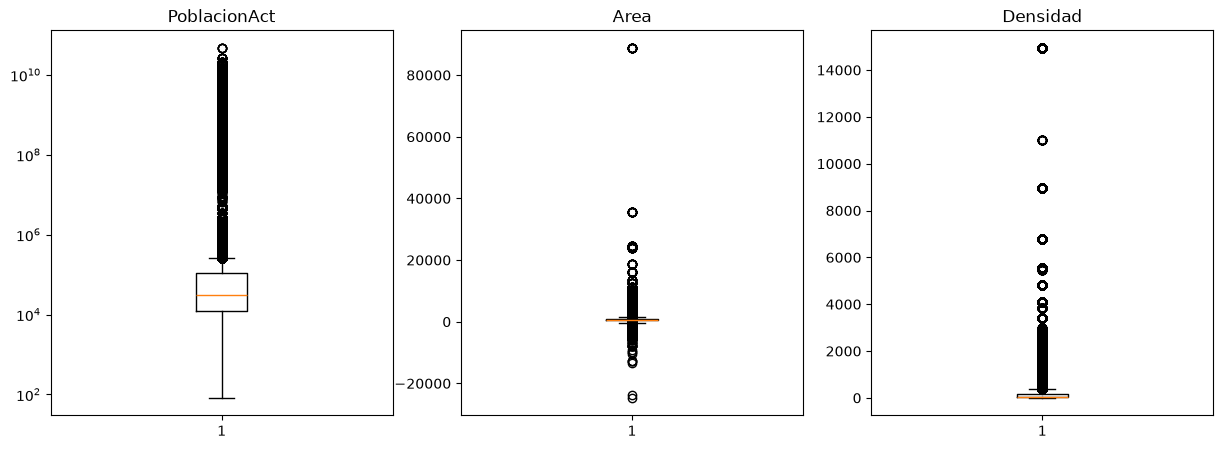

In [18]:
%matplotlib inline
pd_areas = FuenteAreas.select('PoblacionAct', 'Area', 'Densidad').toPandas()
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, c in zip(axes, ['PoblacionAct', 'Area', 'Densidad']):
    ax.boxplot(pd_areas[c].dropna())
    ax.set_title(c)
axes[0].set_yscale('log')
plt.show()

In [19]:
print('Top 10 PoblacionAct:')
FuenteAreas.select('Condado', 'Estado', 'PoblacionAct', 'Fecha').distinct().orderBy(f.desc('PoblacionAct')).show(10)

Top 10 PoblacionAct:
+-----------------+--------+------------+-----+
|          Condado|  Estado|PoblacionAct|Fecha|
+-----------------+--------+------------+-----+
|    Harris County|   Texas|  4.72803E10| 2018|
|Miami-Dade County| Florida|  2.66278E10| 2017|
|    Dallas County|   Texas|  2.58605E10| 2017|
|    Dallas County|   Texas|  2.58605E10| 2018|
|   Tarrant County|   Texas|  2.12648E10| 2018|
|   Tarrant County|   Texas|  2.12648E10| 2017|
|     Bexar County|   Texas|  2.02824E10| 2017|
|   Broward County| Florida|  1.93098E10| 2017|
|   Broward County| Florida|  1.93098E10| 2018|
|     Wayne County|Michigan|  1.77482E10| 2017|
+-----------------+--------+------------+-----+
only showing top 10 rows


El diagrama de caja de `PoblacionAct` (escala logarítmica) muestra valores extremos. Los 10 valores más altos son del orden de 10¹⁰ (por ejemplo, Harris County, Texas: 4,72·10¹⁰), más que la población mundial, así que **no son válidos**. En el ejemplo de consistencia, Duval County aparece con 999.935 y con 9,99935·10⁹, es decir 10.000 veces mayor.

### Consistencia

In [20]:
res_areas = []
base_areas = FuenteAreas.dropDuplicates().cache()
n_areas = base_areas.count()

# DENTRO DE LA FILA
registrar(res_areas, 'Fecha distinta al año al final de IdAreaDeServicio_T',
          base_areas.filter(col('Fecha').cast('string') != f.substring(col('IdAreaDeServicio_T').cast('string'), -4, 4)),
          base_areas.filter(col('IdAreaDeServicio_T').isNotNull()).count())
registrar(res_areas, 'Densidad distinta de round(PoblacionAct / Area) (tolerancia 1)',
          base_areas.filter((col('Area') > 0) & (f.abs(col('Densidad') - f.round(col('PoblacionAct') / col('Area'))) > 1)),
          base_areas.filter(col('Area') > 0).count())

# ENTRE FILAS
g = base_areas.filter(col('IdAreaDeServicio_T').isNotNull()).groupBy('IdAreaDeServicio_T').agg(f.countDistinct('NombreAreaDeServicio').alias('k'))
registrar(res_areas, 'IdAreaDeServicio_T con más de un NombreAreaDeServicio', g.filter('k > 1'), g.count())
g = base_areas.groupBy('Condado', 'Estado').agg(f.countDistinct('IdGeografia_T').alias('k'))
registrar(res_areas, 'Condado+Estado con más de un IdGeografia_T', g.filter('k > 1'), g.count())
g = base_areas.filter(col('IdGeografia_T').isNotNull()).groupBy('IdGeografia_T').agg(f.countDistinct('Condado', 'Estado').alias('k'))
registrar(res_areas, 'IdGeografia_T con más de un Condado+Estado', g.filter('k > 1'), g.count())
g = base_areas.groupBy('Condado', 'Estado', 'Fecha').agg(f.countDistinct('PoblacionAct').alias('k'))
registrar(res_areas, 'Condado+Estado+Fecha con más de una PoblacionAct', g.filter('k > 1'), g.count())
g = base_areas.groupBy('Condado', 'Estado').agg(f.countDistinct('Area').alias('k'))
registrar(res_areas, 'Condado+Estado con más de un Area', g.filter('k > 1'), g.count())

# ENTRE FUENTES
ids_areas = base_areas.select(col('IdAreaDeServicio_T').cast('long').alias('id')).distinct()
ids_planes = FuentePlanesBeneficio.filter(col('IdAreaDeServicio_T').isNotNull()).select(col('IdAreaDeServicio_T').alias('id')).distinct()
registrar(res_areas, 'IdAreaDeServicio_T de PlanesBeneficio sin correspondencia en Areas',
          ids_planes.join(ids_areas, 'id', 'left_anti'), ids_planes.count())

mostrar_resultados(res_areas)

+------------------------------------------------------------------+-----+-----------+-----+
|chequeo                                                           |casos|sobre_total|%    |
+------------------------------------------------------------------+-----+-----------+-----+
|Fecha distinta al año al final de IdAreaDeServicio_T              |4841 |140401     |3.45 |
|Densidad distinta de round(PoblacionAct / Area) (tolerancia 1)    |4772 |138614     |3.44 |
|IdAreaDeServicio_T con más de un NombreAreaDeServicio             |0    |5409       |0.0  |
|Condado+Estado con más de un IdGeografia_T                        |2053 |2282       |89.96|
|IdGeografia_T con más de un Condado+Estado                        |84   |4251       |1.98 |
|Condado+Estado+Fecha con más de una PoblacionAct                  |1778 |4929       |36.07|
|Condado+Estado con más de un Area                                 |1474 |2282       |64.59|
|IdAreaDeServicio_T de PlanesBeneficio sin correspondencia en Areas|10

In [21]:
# Ejemplo: un mismo condado con distintos valores de población / área / IdGeografia
base_areas.filter((col('Condado') == 'Duval County') & (col('Estado') == 'Florida')) \
    .select('IdGeografia_T', 'Condado', 'Estado', 'PoblacionAct', 'Area', 'Densidad', 'Fecha') \
    .distinct().orderBy('Fecha', 'PoblacionAct').show(truncate=False)

+-------------+------------+-------+------------+------+--------+-----+
|IdGeografia_T|Condado     |Estado |PoblacionAct|Area  |Densidad|Fecha|
+-------------+------------+-------+------------+------+--------+-----+
|12031        |Duval County|Florida|999935.0    |774.0 |1292.0  |1800 |
|12031        |Duval County|Florida|999935.0    |774.0 |1292.0  |2017 |
|36093        |Duval County|Florida|999935.0    |774.0 |1292.0  |2017 |
|12031        |Duval County|Florida|999935.0    |-774.0|1292.0  |2017 |
|NULL         |Duval County|Florida|999935.0    |774.0 |1292.0  |2017 |
|12031        |Duval County|Florida|9.99935E9   |774.0 |1292.0  |2017 |
|36093        |Duval County|Florida|999935.0    |774.0 |1292.0  |2018 |
|12031        |Duval County|Florida|999935.0    |774.0 |1292.0  |2018 |
|12031        |Duval County|Florida|999935.0    |-774.0|1292.0  |2018 |
|NULL         |Duval County|Florida|999935.0    |774.0 |1292.0  |2018 |
+-------------+------------+-------+------------+------+--------

**Consistencia** (calculada sobre los 145.242 registros únicos):
- **Dentro de la fila:** 4.841 registros (3,45%) tienen una `Fecha` distinta del año con el que termina su `IdAreaDeServicio_T`, y 4.772 (3,44%) tienen una `Densidad` que no coincide con `PoblacionAct / Area`.
- **Entre filas:** cada `IdAreaDeServicio_T` tiene un único nombre (0 casos). En cambio, **2.053 de 2.282 condados (89,96%) tienen más de un `IdGeografia_T`**, 84 códigos geográficos están asignados a más de un condado, 1.778 combinaciones condado + año (36,07%) tienen más de una población y 1.474 condados (64,59%) tienen más de un área.
- **Entre fuentes:** **1.097 de los 6.496 `IdAreaDeServicio_T` (16,89%) que usa FuentePlanesBeneficio no existen en FuenteAreas.**

El ejemplo de Duval County (Florida) reúne todos los problemas en un solo condado: `IdGeografia_T` 12031, 36093 y NULL, área 774 y -774, población 999.935 y 9,99935·10⁹, y `Fecha` 1800.

### Herramienta de perfilamiento
Reporte de **fg-data-profiling**. Se imprimen las alertas que genera la herramienta para interpretarlas junto con el análisis anterior.

In [22]:
backend_notebook = plt.get_backend()
plt.switch_backend('agg')   # evita que el kernel se quede sin memoria
reporte_areas = ProfileReport(FuenteAreas.toPandas(), title='FuenteAreasDeServicio')
reporte_areas.to_file(OUT / 'reporte_FuenteAreas.html')
plt.switch_backend(backend_notebook)
print(f"Reporte guardado en {OUT / 'reporte_FuenteAreas.html'}")
for alerta in reporte_areas.get_description().alerts:
    print('-', alerta)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 9/9 [00:00<00:00, 48.71it/s]
c:\Users\astri\Desktop\Maestria\CICLO 2 - 1 semestre\Entregables_ETL\.venv\Lib\site-packages\data_profiling\model\pandas\discretize_pandas.py:52: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[9 9 9 ... 9 9 9]' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  discretized_df.loc[:, column] = self._discretize_column(


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Reporte guardado en C:\Users\astri\MIID4103\salidas\reporte_FuenteAreas.html
- Dataset has 43573 (23.1%) duplicate rows
- [Densidad] is highly overall correlated with [PoblacionAct]
- [Estado] is highly overall correlated with [Fecha] and 2 other fields
- [Fecha] is highly overall correlated with [Estado]
- [IdAreaDeServicio_T] is highly overall correlated with [Estado]
- [IdGeografia_T] is highly overall correlated with [Estado]
- [PoblacionAct] is highly overall correlated with [Densidad]
- [IdAreaDeServicio_T] 6288 (3.3%) missing values
- [IdGeografia_T] 6378 (3.4%) missing values
- [Area] 2407 (1.3%) missing values
- [Densidad] 2407 (1.3%) missing values
- [PoblacionAct] is highly skewed(γ1 = 32.63337707519531)
- [Area] is highly skewed(γ1 = 27.90325927734375)


**Interpretación del reporte de la herramienta:**
1. Confirma los **43.573 duplicados (23,1%)** y los faltantes de `IdAreaDeServicio_T` (3,3%), `IdGeografia_T` (3,4%), `Area` y `Densidad` (1,3%).
2. `PoblacionAct` y `Area` tienen una asimetría muy alta (γ1 = 32,6 y 27,9), por los valores extremos y negativos encontrados arriba.
3. La correlación alta entre `Densidad` y `PoblacionAct` es esperable, porque la densidad se calcula a partir de la población.
4. Las correlaciones de `Estado` con `IdGeografia_T`, `IdAreaDeServicio_T` y `Fecha` se deben a que son códigos o categorías, no variables numéricas. La herramienta trata los Id como numéricos, así que esta alerta no implica columnas redundantes.
5. La herramienta **no detecta** la `Fecha` 1800, las áreas negativas, los `IdGeografia_T` inválidos ni las inconsistencias entre filas. Por eso hace falta el análisis propio.

### Conclusión – FuenteAreasDeServicio

El análisis de las cuatro dimensiones muestra que **FuenteAreasDeServicio tiene problemas de calidad importantes, y que deben corregirse antes de usarla en el proyecto**:

- **Unicidad:** es el problema más grande en volumen. 43.573 filas (23,1%) son copias exactas, y aun sin ellas hay 23.263 llaves (IdArea + Condado + Estado) con más de una versión del registro. Es decir, no hay una única fila confiable por condado y área de servicio.
- **Completitud:** los faltantes son bajos. `IdAreaDeServicio_T` tiene 3,33%, `IdGeografia_T` 3,38%, y `Area` y `Densidad` 1,27% cada una. Aun así, los faltantes en los Id son críticos, porque esas filas no se pueden relacionar con las demás tablas.
- **Validez:** hay valores sin sentido de negocio: 6.282 filas con `Fecha` = 1800, 6.177 áreas negativas, 13.713 `IdGeografia_T` con más de 5 dígitos y poblaciones del orden de 10¹⁰, mayores que la población mundial.
- **Consistencia:** el mismo condado aparece con distintos datos. El 89,96% de los condados tiene más de un `IdGeografia_T`, el 64,59% más de un área y el 36,07% de las combinaciones condado + año más de una población. Además, 1.097 áreas de servicio (16,89%) que usa FuentePlanesBeneficio no existen en esta tabla. El caso de Duval County (Florida) reúne todos estos errores en un solo condado.
- **Herramienta:** el reporte de perfilamiento confirmó los duplicados, los faltantes y la alta asimetría de `PoblacionAct` y `Area`. Sin embargo, **no detectó** la fecha 1800, las áreas negativas, los códigos geográficos inválidos ni las inconsistencias entre filas y fuentes, que solo aparecieron con el análisis propio.

Varios errores tienen un patrón que permitiría corregirlos: el año se puede tomar del `IdAreaDeServicio_T`, el área parece tener el signo invertido y la población parece estar multiplicada por un factor. Antes de hacerlo hay que validar estas correcciones con el negocio.

## 2. FuenteCondicionesDePago
### Entendimiento general

In [23]:
FuenteCondicionesPago.printSchema()
print((FuenteCondicionesPago.count(), len(FuenteCondicionesPago.columns)))
FuenteCondicionesPago.orderBy('IdCondicionesDePago_T').show(40, truncate=False)

root
 |-- IdCondicionesDePago_T: integer (nullable = true)
 |-- Descripcion: string (nullable = true)
 |-- Tipo: string (nullable = true)

(31, 3)
+---------------------+--------------------------------+-------------+
|IdCondicionesDePago_T|Descripcion                     |Tipo         |
+---------------------+--------------------------------+-------------+
|9                    |No Charge                       |Coseguridad  |
|17                   |Copay per Day after deductible  |Copago       |
|18                   |No Charge after deductible      |Coseguro     |
|27                   |Coinsurance after deductible    |Coseguro     |
|27                   |Coinsurance after deductible    |Coseguro     |
|34                   |Not Applicable                  |Copagado     |
|36                   |Not Applicable                  |Coseguro     |
|45                   |Coinsurance                     |Coseguro     |
|45                   |Coinsurance                     |Coseguro     |
|

Tenemos **31 filas y 3 columnas**. Es una tabla catálogo: cada fila es una condición de pago, con su descripción y su tipo (copago o coseguro).

### Unicidad

In [24]:
total_cond = FuenteCondicionesPago.count()
distintas_cond = FuenteCondicionesPago.distinct().count()
ids_cond = FuenteCondicionesPago.select('IdCondicionesDePago_T').distinct().count()
print('Total de registros:', total_cond)
print('Registros únicos:', distintas_cond)
print('Filas duplicadas exactas:', total_cond - distintas_cond)
print('IdCondicionesDePago_T distintos:', ids_cond)
print('Ids con más de una versión distinta del registro:',
      FuenteCondicionesPago.distinct().groupBy('IdCondicionesDePago_T').count().filter('count > 1').count())
FuenteCondicionesPago.groupBy('IdCondicionesDePago_T').count().filter('count > 1').orderBy('IdCondicionesDePago_T').show()

Total de registros: 31
Registros únicos: 24
Filas duplicadas exactas: 7
IdCondicionesDePago_T distintos: 23
Ids con más de una versión distinta del registro: 1
+---------------------+-----+
|IdCondicionesDePago_T|count|
+---------------------+-----+
|                   27|    2|
|                   45|    2|
|                   51|    2|
|                  119|    2|
|                  204|    3|
|                  207|    2|
|                  221|    2|
+---------------------+-----+



**Unicidad:** hay **7 filas duplicadas exactas (22,6%)**, así que de 31 registros quedan 24 únicos para 23 Id distintos. El Id **204** tiene dos versiones con descripciones diferentes (*Copay per Day* y *Copay per Stay after deductible*), por lo que el Id no identifica una única condición.

### Completitud

In [25]:
contar_vacios(FuenteCondicionesPago).show(truncate=False)

+---------------------+-----+------+---------+------------+
|columna              |nulos|vacios|texto_NaN|pct_faltante|
+---------------------+-----+------+---------+------------+
|IdCondicionesDePago_T|0    |0     |0        |0.0         |
|Descripcion          |0    |0     |0        |0.0         |
|Tipo                 |0    |0     |2        |6.45        |
+---------------------+-----+------+---------+------------+



In [26]:
cardinalidad(FuenteCondicionesPago).show(truncate=False)

+---------------------+---------+-------------+
|columna              |distintos|pct_distintos|
+---------------------+---------+-------------+
|IdCondicionesDePago_T|23       |74.19        |
|Descripcion          |17       |54.84        |
|Tipo                 |6        |19.35        |
+---------------------+---------+-------------+



**Completitud:** no hay nulos ni vacíos, pero `Tipo` tiene **2 valores con el texto `NaN`** (Id 221), es decir 6,45% faltante. **Cardinalidad:** `IdCondicionesDePago_T` (74,19%) y `Descripcion` (54,84%) superan el 50%, algo esperable en un catálogo tan pequeño.

### Validez

In [27]:
FuenteCondicionesPago.groupBy('Tipo').count().orderBy(f.desc('count')).show()
print("Tipo fuera de {'Copago', 'Coseguro'}:",
      FuenteCondicionesPago.filter(~col('Tipo').isin('Copago', 'Coseguro')).count())
FuenteCondicionesPago.filter(~col('Tipo').isin('Copago', 'Coseguro')).orderBy('IdCondicionesDePago_T').show(truncate=False)

+-------------+-----+
|         Tipo|count|
+-------------+-----+
|       Copago|   19|
|     Coseguro|    7|
|          NaN|    2|
|SinTipoCopago|    1|
|  Coseguridad|    1|
|     Copagado|    1|
+-------------+-----+

Tipo fuera de {'Copago', 'Coseguro'}: 5
+---------------------+-------------------------------+-------------+
|IdCondicionesDePago_T|Descripcion                    |Tipo         |
+---------------------+-------------------------------+-------------+
|9                    |No Charge                      |Coseguridad  |
|34                   |Not Applicable                 |Copagado     |
|68                   |Copay per Stay after deductible|SinTipoCopago|
|221                  |Copay per Stay                 |NaN          |
|221                  |Copay per Stay                 |NaN          |
+---------------------+-------------------------------+-------------+



In [28]:
FuenteCondicionesPago.groupBy('Descripcion').count().orderBy(f.desc('count')).show(truncate=False)

+--------------------------------+-----+
|Descripcion                     |count|
+--------------------------------+-----+
|No Charge after deductible      |3    |
|No Charge                       |3    |
|Copay per Stay                  |3    |
|Coinsurance                     |3    |
|Copay per Stay after deductible |3    |
|Copay per Day with deductible   |2    |
|Coinsurance after deductible    |2    |
|Copay                           |2    |
|Not Applicable                  |2    |
|Copay per Day                   |1    |
|Copay per Day after deductible  |1    |
|Copay before deductible         |1    |
|Copay per Day before deductible |1    |
|Copay per Stay with deductible  |1    |
|Copay per Stay before deductible|1    |
|Copay with deductible           |1    |
|Copay after deductible          |1    |
+--------------------------------+-----+



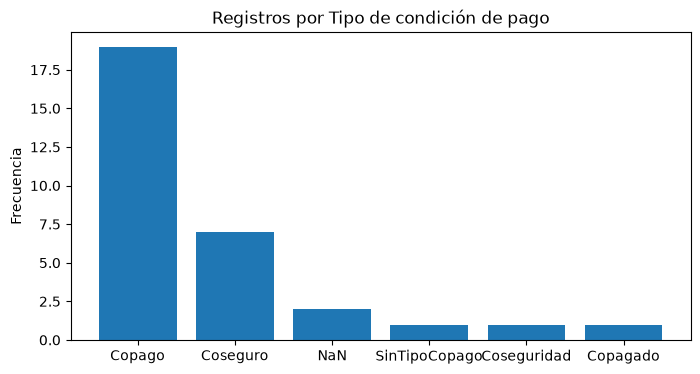

In [29]:
pd_tipo = FuenteCondicionesPago.groupBy('Tipo').count().orderBy(f.desc('count')).toPandas()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(pd_tipo['Tipo'], pd_tipo['count'])
ax.set_title('Registros por Tipo de condición de pago')
ax.set_ylabel('Frecuencia')
plt.show()

**Validez:** `Tipo` toma 6 valores cuando solo deberían existir `Copago` y `Coseguro`. Hay **5 filas fuera del dominio**: `Coseguridad` (Id 9), `Copagado` (Id 34), `SinTipoCopago` (Id 68) y `NaN` (Id 221, dos veces). Las descripciones no presentan problemas de formato.

### Consistencia

In [30]:
res_cond = []
base_cond = FuenteCondicionesPago.dropDuplicates().cache()
n_cond = base_cond.count()

# DENTRO DE LA FILA
copay = col('Descripcion').startswith('Copay')
coins = col('Descripcion').startswith('Coinsurance')
registrar(res_cond, "Descripcion 'Copay...' con Tipo distinto de 'Copago'",
          base_cond.filter(copay & (col('Tipo') != 'Copago')), base_cond.filter(copay).count())
registrar(res_cond, "Descripcion 'Coinsurance...' con Tipo distinto de 'Coseguro'",
          base_cond.filter(coins & (col('Tipo') != 'Coseguro')), base_cond.filter(coins).count())

# ENTRE FILAS
g = base_cond.groupBy('IdCondicionesDePago_T').agg(f.countDistinct('Descripcion').alias('k'))
registrar(res_cond, 'IdCondicionesDePago_T con más de una Descripcion', g.filter('k > 1'), g.count())
g = base_cond.groupBy('Descripcion').agg(f.countDistinct('IdCondicionesDePago_T').alias('k'))
registrar(res_cond, 'Descripcion asociada a más de un IdCondicionesDePago_T', g.filter('k > 1'), g.count())

# ENTRE FUENTES
tipos_cond = base_cond.select(col('IdCondicionesDePago_T').alias('id'), 'Tipo').distinct()
copago_planes = FuentePlanesBeneficio.select(col('IdCondicionDePagoCopago_T').alias('id'))
coseguro_planes = FuentePlanesBeneficio.select(col('IdCondicionDePagoCoseguro_T').alias('id'))
registrar(res_cond, 'IdCondicionDePagoCopago_T de PlanesBeneficio sin correspondencia',
          copago_planes.distinct().join(tipos_cond, 'id', 'left_anti'), copago_planes.distinct().count())
registrar(res_cond, 'IdCondicionDePagoCoseguro_T de PlanesBeneficio sin correspondencia',
          coseguro_planes.distinct().join(tipos_cond, 'id', 'left_anti'), coseguro_planes.distinct().count())
registrar(res_cond, "Filas de PlanesBeneficio cuya condición de copago no es Tipo 'Copago'",
          copago_planes.join(tipos_cond, 'id').filter(col('Tipo') != 'Copago'), copago_planes.count())
registrar(res_cond, "Filas de PlanesBeneficio cuya condición de coseguro no es Tipo 'Coseguro'",
          coseguro_planes.join(tipos_cond, 'id').filter(col('Tipo') != 'Coseguro'), coseguro_planes.count())

mostrar_resultados(res_cond)

+-------------------------------------------------------------------------+-----+-----------+-----+
|chequeo                                                                  |casos|sobre_total|%    |
+-------------------------------------------------------------------------+-----+-----------+-----+
|Descripcion 'Copay...' con Tipo distinto de 'Copago'                     |2    |15         |13.33|
|Descripcion 'Coinsurance...' con Tipo distinto de 'Coseguro'             |0    |3          |0.0  |
|IdCondicionesDePago_T con más de una Descripcion                         |1    |23         |4.35 |
|Descripcion asociada a más de un IdCondicionesDePago_T                   |7    |17         |41.18|
|IdCondicionDePagoCopago_T de PlanesBeneficio sin correspondencia         |0    |14         |0.0  |
|IdCondicionDePagoCoseguro_T de PlanesBeneficio sin correspondencia       |0    |5          |0.0  |
|Filas de PlanesBeneficio cuya condición de copago no es Tipo 'Copago'    |16409|36036      |45.54|


In [31]:
base_cond.filter(col('Descripcion').isin('Copay per Stay', 'Coinsurance', 'No Charge', 'Not Applicable', 'No Charge after deductible')) \
    .orderBy('Descripcion', 'IdCondicionesDePago_T').show(truncate=False)

+---------------------+--------------------------+-----------+
|IdCondicionesDePago_T|Descripcion               |Tipo       |
+---------------------+--------------------------+-----------+
|45                   |Coinsurance               |Coseguro   |
|135                  |Coinsurance               |Coseguro   |
|221                  |Copay per Stay            |NaN        |
|663                  |Copay per Stay            |Copago     |
|9                    |No Charge                 |Coseguridad|
|51                   |No Charge                 |Copago     |
|18                   |No Charge after deductible|Coseguro   |
|207                  |No Charge after deductible|Copago     |
|34                   |Not Applicable            |Copagado   |
|36                   |Not Applicable            |Coseguro   |
+---------------------+--------------------------+-----------+



**Consistencia:**
- **Dentro de la fila:** 2 de los 15 registros únicos con descripción *Copay...* no tienen `Tipo` = `Copago` (Id 68 `SinTipoCopago` e Id 221 `NaN`). Todas las descripciones *Coinsurance...* tienen `Tipo` = `Coseguro`.
- **Entre filas:** el Id 204 tiene dos descripciones. Además, 7 de 17 descripciones están en más de un Id. En *No Charge* y *Not Applicable* tiene sentido, porque existe una versión para copago y otra para coseguro (por ejemplo, 51 Copago y 9 Coseguridad). En cambio, *Coinsurance* (45 y 135) y *Copay per Stay* (221 y 663) se repiten con el mismo tipo.
- **Entre fuentes:** todas las condiciones que usa FuentePlanesBeneficio existen en el catálogo. Sin embargo, **16.409 filas de planes (45,54%)** usan como copago una condición cuyo tipo no es `Copago` (Id 34 `Copagado`, Id 68 `SinTipoCopago`, Id 221 `NaN`), y **471 filas (1,31%)** usan como coseguro el Id 9 (`Coseguridad`). Esto confirma que esos tipos son errores de escritura de `Copago` y `Coseguro`.

### Herramienta de perfilamiento

In [32]:
plt.switch_backend('agg')
reporte_cond = ProfileReport(FuenteCondicionesPago.toPandas(), title='FuenteCondicionesDePago')
reporte_cond.to_file(OUT / 'reporte_FuenteCondicionesPago.html')
plt.switch_backend(backend_notebook)
print(f"Reporte guardado en {OUT / 'reporte_FuenteCondicionesPago.html'}")
for alerta in reporte_cond.get_description().alerts:
    print('-', alerta)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 3/3 [00:00<00:00, 585.42it/s]
c:\Users\astri\Desktop\Maestria\CICLO 2 - 1 semestre\Entregables_ETL\.venv\Lib\site-packages\data_profiling\model\pandas\discretize_pandas.py:52: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[2 2 0 1 0 1 0 3 2 2 0 0 1 2 0 1 0 0 3 0 9 1 9 2 0 3 2 0 2 1 0]' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  discretized_df.loc[:, column] = self._discretize_column(


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Reporte guardado en C:\Users\astri\MIID4103\salidas\reporte_FuenteCondicionesPago.html
- Dataset has 7 (22.6%) duplicate rows


**Interpretación del reporte de la herramienta:** la única alerta son los **7 duplicados (22,6%)**. Con solo 31 filas, la herramienta no detecta los valores inválidos de `Tipo` (`NaN` lo toma como un texto más), ni el Id 204 con dos descripciones, ni las inconsistencias con PlanesBeneficio. Como dice el tutorial, el reporte sin interpretación y sin análisis propio no es suficiente.

### Conclusión – FuenteCondicionesDePago

Es una tabla pequeña (31 filas), pero **sus errores tienen un impacto alto, porque se propagan a FuentePlanesBeneficio**:

- **Unicidad:** 7 filas (22,6%) son duplicados exactos, y el Id 204 tiene dos descripciones distintas. Por eso el Id no identifica de forma única una condición de pago.
- **Completitud:** no hay nulos ni vacíos, pero `Tipo` tiene 2 valores con el texto `NaN` (Id 221). Son faltantes disfrazados que una revisión de nulos no detecta.
- **Validez:** `Tipo` debería tomar solo `Copago` o `Coseguro`, pero tiene 6 valores distintos: hay 5 filas con `Coseguridad`, `Copagado`, `SinTipoCopago` y `NaN`.
- **Consistencia:** dentro de la tabla, 2 condiciones con descripción *Copay* no tienen tipo `Copago`. Entre fuentes, todos los Id que usa PlanesBeneficio existen en el catálogo, pero por los tipos mal escritos **16.409 filas de planes (45,54%)** quedan asociadas como copago a una condición que no es `Copago`, y **471 (1,31%)** como coseguro a una que no es `Coseguro`.
- **Herramienta:** el reporte solo alertó sobre los duplicados. No identificó los tipos inválidos, el texto `NaN` ni el Id con dos descripciones.

La corrección es sencilla: eliminar los duplicados, homologar `Tipo` a {Copago, Coseguro} según la descripción y el uso que tienen en PlanesBeneficio, y que el negocio defina la descripción correcta del Id 204. Por su efecto sobre casi la mitad de los planes, esta limpieza debería hacerse primero.

## 3. FuentePlanesBeneficio

### Entendimiento general de los datos
Antes de evaluar la calidad se revisa la estructura (esquema), el tamaño y qué representa una fila de cada fuente.

In [33]:
FuentePlanesBeneficio.printSchema()

root
 |-- IdTipoBeneficio_T: long (nullable = true)
 |-- IdAreaDeServicio_T: long (nullable = true)
 |-- IdCondicionDePagoCopago_T: integer (nullable = true)
 |-- IdCondicionDePagoCoseguro_T: integer (nullable = true)
 |-- IdNivelServicio_T: integer (nullable = true)
 |-- IdPlan_T: string (nullable = true)
 |-- Fecha: string (nullable = true)
 |-- IdProveedor_T: integer (nullable = true)
 |-- valorCopago: integer (nullable = true)
 |-- valorCoseguro: integer (nullable = true)
 |-- cantidadLimite: integer (nullable = true)



In [34]:
print('FuentePlanesBeneficio (filas, columnas):', (FuentePlanesBeneficio.count(), len(FuentePlanesBeneficio.columns)))

FuentePlanesBeneficio (filas, columnas): (36036, 11)


**¿Qué es una fila de cada fuente?**
- **FuentePlanesBeneficio:** un tipo de beneficio (`IdTipoBeneficio_T`) ofrecido dentro de un plan (`IdPlan_T`) de un proveedor (`IdProveedor_T`), para un nivel de servicio (`IdNivelServicio_T`) y un año (`Fecha`), con sus condiciones de pago (copago y coseguro) y, cuando aplica, una cantidad límite.

In [35]:
FuentePlanesBeneficio.select('valorCopago', 'valorCoseguro', 'cantidadLimite', 'IdNivelServicio_T').summary().show()

+-------+------------------+------------------+-----------------+------------------+
|summary|       valorCopago|     valorCoseguro|   cantidadLimite| IdNivelServicio_T|
+-------+------------------+------------------+-----------------+------------------+
|  count|             36036|             36036|             5465|             36036|
|   mean| 9.778416028416029| 24.29279054279054|129.3313815187557|1.9995282495282496|
| stddev|100.41137967701272|36.959755494458506|951.2795862330698|0.8173400355652516|
|    min|                 0|                 0|                1|                 1|
|    25%|                 0|                 0|                1|                 1|
|    50%|                 0|                 0|               25|                 2|
|    75%|                 0|                50|               40|                 3|
|    max|              3500|               100|            30000|                 3|
+-------+------------------+------------------+-----------------+

### Completitud
Se crea la función `contar_vacios`, además de los nulos, las **cadenas vacías** en las columnas de texto: un texto vacío no es nulo para Spark, pero tampoco aporta información.

In [36]:
def contar_vacios(df):
    total = df.count()
    resultados = {}
    for c, tipo in df.dtypes:
        condicion = col(c).isNull()
        if tipo == 'string':
            condicion = condicion | (f.trim(col(c)) == '')
        vacios = df.filter(condicion).count()
        if vacios != 0:
            print(f'número de vacíos para columna {c}: {vacios} ({vacios / total:.1%})')
            resultados[c] = vacios
    return resultados

print('FuentePlanesBeneficio:')
vacios_planes = contar_vacios(FuentePlanesBeneficio)

FuentePlanesBeneficio:
número de vacíos para columna IdTipoBeneficio_T: 2086 (5.8%)
número de vacíos para columna IdAreaDeServicio_T: 2041 (5.7%)
número de vacíos para columna IdPlan_T: 2053 (5.7%)
número de vacíos para columna cantidadLimite: 30571 (84.8%)


In [37]:
# ¿Los faltantes ocurren en las mismas filas?
FuentePlanesBeneficio.select(
    f.sum(when(col('IdTipoBeneficio_T').isNull() & col('IdAreaDeServicio_T').isNull(), 1).otherwise(0)).alias('tipo_y_area_nulos'),
    f.sum(when(col('IdTipoBeneficio_T').isNull() & (f.trim(col('IdPlan_T')) == ''), 1).otherwise(0)).alias('tipo_nulo_y_plan_vacio'),
    f.sum(when(col('IdTipoBeneficio_T').isNull() | col('IdAreaDeServicio_T').isNull() | (f.trim(col('IdPlan_T')) == ''), 1).otherwise(0)).alias('filas_con_algun_faltante')
).show()

+-----------------+----------------------+------------------------+
|tipo_y_area_nulos|tipo_nulo_y_plan_vacio|filas_con_algun_faltante|
+-----------------+----------------------+------------------------+
|                0|                     0|                    6180|
+-----------------+----------------------+------------------------+



**Conclusiones de completitud**

*FuentePlanesBeneficio*
- `IdTipoBeneficio_T` tiene 2.086 nulos (5,8 %) e `IdAreaDeServicio_T` tiene 2.041 (5,7 %). Sin el tipo de beneficio la fila no se puede relacionar con el catálogo, y sin área no se sabe dónde aplica el plan.
- `IdPlan_T` no tiene nulos, pero sí 2.053 **cadenas vacías** (5,7 %). Este faltante "escondido" no lo detecta `isNull()` ni la herramienta de perfilamiento.
- `cantidadLimite` está vacía en 30.571 filas (84,8 %). Esto puede ser esperado si la mayoría de beneficios no tienen límite cuantitativo, pero hay que confirmarlo con el negocio.
- Los faltantes de tipo, área y plan nunca coinciden en la misma fila: en total 6.180 filas (17,1 %) tienen alguno. Eliminar todas las filas incompletas implicaría perder ese porcentaje de los datos.
- `Fecha` tampoco tiene nulos, pero 2.052 filas traen `1920-12-31`, que parece un valor por defecto en lugar de un dato real (ver Validez).

### Unicidad
Primero se buscan duplicados totales (filas idénticas) y después duplicados por la llave de cada tabla, es decir, la combinación de atributos que debería identificar una fila.

In [38]:
for nombre, df in [('FuentePlanesBeneficio', FuentePlanesBeneficio), ('FuenteTiposBeneficio', FuenteTiposBeneficio)]:
    total, distintos = df.count(), df.distinct().count()
    print(f'{nombre}: {total} filas, {distintos} distintas, {total - distintos} duplicados totales ({(total - distintos) / total:.1%})')

FuentePlanesBeneficio: 36036 filas, 27543 distintas, 8493 duplicados totales (23.6%)
FuenteTiposBeneficio: 849 filas, 578 distintas, 271 duplicados totales (31.9%)


En **FuentePlanesBeneficio** una fila debería ser única por plan, tipo de beneficio, año y nivel de servicio (`IdPlan_T`, `IdTipoBeneficio_T`, `Fecha`, `IdNivelServicio_T`). Se revisa sobre las filas sin duplicados totales y con plan informado:

In [39]:
planes_unicos = FuentePlanesBeneficio.distinct()
llave_planes = ['IdPlan_T', 'IdTipoBeneficio_T', 'Fecha', 'IdNivelServicio_T']
repetidas = planes_unicos.filter(f.trim(col('IdPlan_T')) != '').groupBy(llave_planes).count().filter(col('count') > 1)
filas_involucradas = repetidas.agg(f.sum('count')).first()[0]
print('Combinaciones de llave repetidas:', repetidas.count())
print('Filas involucradas:', filas_involucradas, '| filas sobrantes:', filas_involucradas - repetidas.count())
repetidas.orderBy(col('count').desc()).show(5)

Combinaciones de llave repetidas: 542
Filas involucradas: 2043 | filas sobrantes: 1501
+-----------------+-----------------+----------+-----------------+-----+
|         IdPlan_T|IdTipoBeneficio_T|     Fecha|IdNivelServicio_T|count|
+-----------------+-----------------+----------+-----------------+-----+
|40047MI0070001-00|             NULL|2017-12-31|                2|   16|
|40047MI0070001-00|             NULL|2017-12-31|                1|   15|
|40047MI0070001-00|             NULL|2017-12-31|                3|   14|
|74917MI0010003-01|              825|2017-12-31|                1|   12|
|74917MI0010003-01|              825|2017-12-31|                3|   10|
+-----------------+-----------------+----------+-----------------+-----+
only showing top 5 rows


In [40]:
planes_unicos.filter((col('IdPlan_T') == '40047MI0070001-00') & (col('IdTipoBeneficio_T') == 5) & (col('Fecha') == '2017-12-31')) \
    .orderBy('IdNivelServicio_T').show()

+-----------------+------------------+-------------------------+---------------------------+-----------------+-----------------+----------+-------------+-----------+-------------+--------------+
|IdTipoBeneficio_T|IdAreaDeServicio_T|IdCondicionDePagoCopago_T|IdCondicionDePagoCoseguro_T|IdNivelServicio_T|         IdPlan_T|     Fecha|IdProveedor_T|valorCopago|valorCoseguro|cantidadLimite|
+-----------------+------------------+-------------------------+---------------------------+-----------------+-----------------+----------+-------------+-----------+-------------+--------------+
|                5|          51632017|                      238|                         45|                1|40047MI0070001-00|2017-12-31|        40047|          0|            0|          NULL|
|                5|          52222017|                      238|                         45|                1|40047MI0070001-00|2017-12-31|        40047|          0|            0|          NULL|
|                5|      

**Conclusiones de unicidad**
- **FuentePlanesBeneficio** tiene 8.493 filas completamente repetidas (23,6 %), que deben eliminarse. Después de quitarlas, todavía hay 542 combinaciones de plan, tipo, año y nivel de servicio repetidas (2.043 filas, 1.501 sobrantes). En el ejemplo del plan `40047MI0070001-00` las filas repetidas solo cambian en `IdAreaDeServicio_T`. Esto sugiere que la llave real incluye el área de servicio, pero hay que confirmarlo con el negocio.

### Validez
Se revisa el formato de las fechas y de los identificadores de texto, el dominio de las variables categóricas y el rango de las variables numéricas.

#### Formato de `Fecha` en FuentePlanesBeneficio
Se usa una expresión regular para el formato `YYYY-MM-DD`, como en el tutorial.

In [41]:
regex_fecha = r'^[0-2]\d{3}-(0[1-9]|1[0-2])-(0[1-9]|[1-2][0-9]|3[0-1])$'
no_cumplen = FuentePlanesBeneficio.filter(~col('Fecha').rlike(regex_fecha))
print('Filas con Fecha fuera del formato YYYY-MM-DD:', no_cumplen.count())
FuentePlanesBeneficio.groupBy('Fecha').count().orderBy('Fecha').show()

Filas con Fecha fuera del formato YYYY-MM-DD: 2056
+-----------+-----+
|      Fecha|count|
+-----------+-----+
| 1920-12-31| 2052|
| 2017-12-31|16134|
| 2018-12-31|15794|
|Dec 31,2017| 1029|
|Dec 31,2018| 1027|
+-----------+-----+



#### Formato de `IdPlan_T`
Los identificadores de plan siguen el patrón: 5 dígitos del proveedor, 2 letras del estado, 7 dígitos, un guion y 2 dígitos de la variante (ej. `16842FL0070128-03`).

In [42]:
regex_plan = r'^\d{5}[A-Z]{2}\d{7}-\d{2}$'
FuentePlanesBeneficio.filter(~col('IdPlan_T').rlike(regex_plan)).groupBy('IdPlan_T').count().show()

+--------+-----+
|IdPlan_T|count|
+--------+-----+
|        | 2053|
+--------+-----+



#### Rango de las variables numéricas de FuentePlanesBeneficio
`valorCoseguro` es un porcentaje (0 a 100), `valorCopago` es un valor en dinero y `cantidadLimite` es una cantidad positiva. Además se revisan los dominios de los identificadores de condición de pago y de nivel de servicio.

In [43]:
FuentePlanesBeneficio.select(
    f.sum(when((col('valorCoseguro') < 0) | (col('valorCoseguro') > 100), 1).otherwise(0)).alias('coseguro_fuera_0_100'),
    f.sum(when(col('valorCopago') < 0, 1).otherwise(0)).alias('copago_negativo'),
    f.sum(when(col('valorCopago') > 100, 1).otherwise(0)).alias('copago_mayor_100'),
    f.sum(when(col('cantidadLimite') <= 0, 1).otherwise(0)).alias('limite_no_positivo'),
    f.sum(when(col('cantidadLimite') > 100, 1).otherwise(0)).alias('limite_mayor_100')
).show()

for c in ['IdNivelServicio_T', 'IdCondicionDePagoCopago_T', 'IdCondicionDePagoCoseguro_T']:
    FuentePlanesBeneficio.groupBy(c).count().orderBy(col('count').desc()).show(20)

+--------------------+---------------+----------------+------------------+----------------+
|coseguro_fuera_0_100|copago_negativo|copago_mayor_100|limite_no_positivo|limite_mayor_100|
+--------------------+---------------+----------------+------------------+----------------+
|                   0|              0|             441|                 0|             319|
+--------------------+---------------+----------------+------------------+----------------+

+-----------------+-----+
|IdNivelServicio_T|count|
+-----------------+-----+
|                1|12045|
|                3|12028|
|                2|11963|
+-----------------+-----+

+-------------------------+-----+
|IdCondicionDePagoCopago_T|count|
+-------------------------+-----+
|                      238|18123|
|                       34|16364|
|                       51|  612|
|                      207|  325|
|                      153|  290|
|                      170|  124|
|                      102|   50|
|               

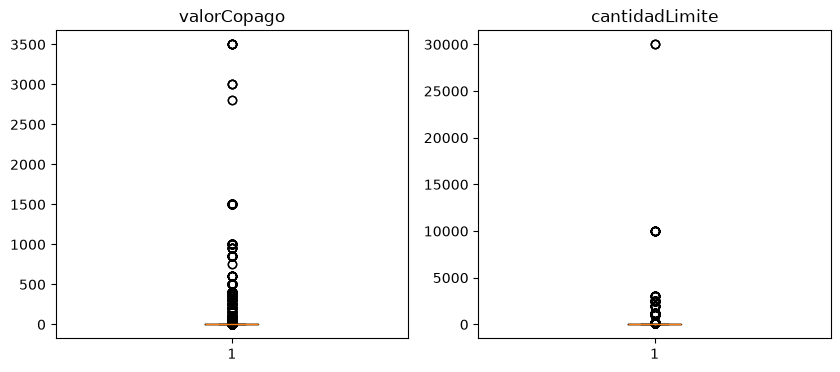

+--------------+-----+
|cantidadLimite|count|
+--------------+-----+
|         30000|    3|
|         10000|   16|
|          3000|   23|
|          2500|   60|
|          2000|   24|
+--------------+-----+
only showing top 5 rows


In [44]:
%matplotlib inline
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.set_title('valorCopago')
ax1.boxplot([row[0] for row in FuentePlanesBeneficio.select('valorCopago').dropna().collect()])
ax2.set_title('cantidadLimite')
ax2.boxplot([row[0] for row in FuentePlanesBeneficio.select('cantidadLimite').dropna().collect()])
plt.show()

FuentePlanesBeneficio.groupBy('cantidadLimite').count().orderBy(col('cantidadLimite').desc()).show(5)

**Conclusiones de validez**
- **Fecha (planes):** 2.056 filas traen otro formato (`Dec 31,2017` y `Dec 31,2018`). Es solo un problema de formato y se puede estandarizar a `YYYY-MM-DD`. Además, 2.052 filas tienen `1920-12-31`: el formato es correcto pero el valor no tiene sentido, se recomienda validar con la empresa si este es un error en la escritura o identificar porque sale este registro, porque los demás datos son de 2017 y 2018. Es un valor por defecto que esconde un faltante. En Consistencia se muestra que el año real se puede recuperar.
- **IdPlan_T:** todos los planes informados cumplen el patrón. Solo fallan los 2.053 vacíos.
- **Rangos:** `valorCoseguro` está siempre entre 0 y 100 y no hay valores negativos. `valorCopago` es 0 en la mayoría de filas, pero 441 filas superan 100 (hasta 3.500). `cantidadLimite` supera 100 en 319 filas y llega hasta 30.000. Estos valores extremos pueden ser válidos si el límite está en dólares (ver `UnidadDelLimite` = `Dollars per ...`), así que se reportan como atípicos para confirmar, no como errores.
- Los dominios de `IdNivelServicio_T` (1, 2, 3) y de las condiciones de pago son pequeños y no muestran valores extraños. Habría que validarlos contra `FuenteCondicionesDePago`.

### Consistencia
Se revisa la coherencia **dentro de una fila** (atributos que dependen entre sí) y **entre fuentes** (integridad referencial entre planes y tipos de beneficio).

#### Proveedor contra plan
Los 5 primeros dígitos de `IdPlan_T` corresponden al proveedor, así que deberían coincidir con `IdProveedor_T`.

In [45]:
planes_informados = FuentePlanesBeneficio.filter(f.trim(col('IdPlan_T')) != '')
print('Planes informados:', planes_informados.count())
print('Proveedor distinto al prefijo del plan:',
      planes_informados.filter(f.substring('IdPlan_T', 1, 5) != col('IdProveedor_T').cast('string')).count())

Planes informados: 33983
Proveedor distinto al prefijo del plan: 0


#### Área de servicio contra año
Los últimos 4 dígitos de `IdAreaDeServicio_T` parecen corresponder al año del plan (ej. área `10382017` con fecha `2017-12-31`). Se compara ese sufijo con el año de `Fecha`:

In [46]:
areas = FuentePlanesBeneficio.filter(col('IdAreaDeServicio_T').isNotNull()) \
    .withColumn('sufijo_area', f.substring(col('IdAreaDeServicio_T').cast('string'), -4, 4)) \
    .withColumn('anio_fecha', f.regexp_extract('Fecha', r'(\d{4})', 1))
areas.groupBy('anio_fecha', 'sufijo_area').count().orderBy('anio_fecha', 'sufijo_area').show()

+----------+-----------+-----+
|anio_fecha|sufijo_area|count|
+----------+-----------+-----+
|      1920|       2017|  986|
|      1920|       2018| 1066|
|      2017|       2017|15019|
|      2017|       4035| 1066|
|      2018|       2018|14849|
|      2018|       4036| 1009|
+----------+-----------+-----+



**Conclusiones de consistencia**
- **Proveedor contra plan:** todas las filas con plan informado son coherentes, porque el prefijo de `IdPlan_T` siempre coincide con `IdProveedor_T`. Esto también muestra que `IdProveedor_T` es redundante con el plan.
- **Área contra año:** en 29.868 filas el sufijo del área coincide con el año de `Fecha`. Hay tres excepciones:
  - Las 2.052 filas con `Fecha = 1920-12-31` tienen sufijo 2017 (986) o 2018 (1.066) en el área. Esto confirma que 1920 es un valor por defecto y que el año real se puede recuperar del área.
  - 1.066 filas de 2017 tienen sufijo 4035 y 1.009 filas de 2018 tienen sufijo 4036 (4035 = 2017 + 2018 y 4036 = 2018 + 2018). Esto sugiere un error al construir la llave del área que se debe consultar.
  - Además, el área viene como entero, así que pierde los ceros a la izquierda y tiene longitudes de 5 a 9 dígitos.

### Herramienta de perfilamiento

In [61]:
backend_notebook = plt.get_backend()
plt.switch_backend('agg')   # evita que el kernel se quede sin memoria
reporte = ProfileReport(FuentePlanesBeneficio.toPandas(), title='Perfilamiento planes_beneficio')
reporte.to_file(OUT / 'reporte_planes_beneficio.html')
print(f"Reporte guardado en {OUT / 'reporte_planes_beneficio.html'}")
plt.switch_backend(backend_notebook)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 11/11 [00:00<00:00, 216.80it/s]
c:\Users\astri\Desktop\Maestria\CICLO 2 - 1 semestre\Entregables_ETL\.venv\Lib\site-packages\data_profiling\model\pandas\discretize_pandas.py:52: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 9 9 ... 9 9 0]' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  discretized_df.loc[:, column] = self._discretize_column(
c:\Users\astri\Desktop\Maestria\CICLO 2 - 1 semestre\Entregables_ETL\.venv\Lib\site-packages\data_profiling\model\pandas\discretize_pandas.py:52: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[4 9 9 ... 2 9 9]' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  discretized_df.loc[:, column] = self._discretize_column(
c:\Users\astri\Desktop\Maestria\CICLO 2 - 1 semestre\Entregables_ETL\.venv\Lib\site-packages\

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Reporte guardado en C:\Users\astri\MIID4103\salidas\reporte_planes_beneficio.html


## 4. FuenteTiposBeneficio

### Entendimiento general de los datos

In [47]:
FuenteTiposBeneficio.printSchema()

root
 |-- IdTipoBeneficio_T: integer (nullable = true)
 |-- Nombre: string (nullable = true)
 |-- UnidadDelLimite: string (nullable = true)
 |-- EsEHB: string (nullable = true)
 |-- EstaCubiertaPorSeguro: string (nullable = true)
 |-- TieneLimiteCuantitativo: string (nullable = true)
 |-- ExcluidoDelDesembolsoMaximoDentroDeLaRed: string (nullable = true)
 |-- ExcluidoDelDesembolsoMaximoFueraDeLaRed: string (nullable = true)
 |-- Fecha: integer (nullable = true)



In [48]:
print('FuenteTiposBeneficio (filas, columnas):', (FuenteTiposBeneficio.count(), len(FuenteTiposBeneficio.columns)))

FuenteTiposBeneficio (filas, columnas): (849, 9)


**¿Qué es una fila de cada fuente?**
- **FuenteTiposBeneficio:** el catálogo de tipos de beneficio por año (`Fecha` es solo el año). Describe el nombre del beneficio, la unidad del límite y varias banderas Yes/No (si es EHB, si está cubierto por el seguro, si tiene límite cuantitativo y si se excluye del desembolso máximo dentro o fuera de la red).

### Completitud

In [49]:
print('FuenteTiposBeneficio:')
vacios_tipos = contar_vacios(FuenteTiposBeneficio)

FuenteTiposBeneficio:


número de vacíos para columna UnidadDelLimite: 559 (65.8%)


**Conclusiones de completitud**

*FuenteTiposBeneficio*
- No hay nulos. `UnidadDelLimite` está vacía en 559 filas (65,8 %), lo cual es esperado cuando el beneficio no tiene límite cuantitativo. Esa relación se valida en Consistencia.

### Unicidad

En **FuenteTiposBeneficio** la llave esperada es el tipo de beneficio por año (`IdTipoBeneficio_T`, `Fecha`). Se revisa sobre las filas sin duplicados totales:

In [50]:
tipos_unicos = FuenteTiposBeneficio.distinct()
print('Filas sin duplicados totales:', tipos_unicos.count())
print('Ids de tipo distintos:', tipos_unicos.select('IdTipoBeneficio_T').distinct().count())
print('Combinaciones (Id, Fecha) distintas:', tipos_unicos.select('IdTipoBeneficio_T', 'Fecha').distinct().count())

versiones = tipos_unicos.groupBy('IdTipoBeneficio_T', 'Fecha').count().filter(col('count') > 1)
print('Combinaciones (Id, Fecha) con más de una versión:', versiones.count())
versiones.orderBy(col('count').desc()).show(5)

# Relación Id <-> Nombre
print('Nombres con más de un Id:', tipos_unicos.groupBy('Nombre').agg(f.countDistinct('IdTipoBeneficio_T').alias('ids')).filter(col('ids') > 1).count())
print('Ids con más de un Nombre:', tipos_unicos.groupBy('IdTipoBeneficio_T').agg(f.countDistinct('Nombre').alias('nombres')).filter(col('nombres') > 1).count())

Filas sin duplicados totales: 578
Ids de tipo distintos: 178
Combinaciones (Id, Fecha) distintas: 218
Combinaciones (Id, Fecha) con más de una versión: 117
+-----------------+-----+-----+
|IdTipoBeneficio_T|Fecha|count|
+-----------------+-----+-----+
|              865| 2017|   16|
|              190| 2017|   14|
|              830| 2017|   13|
|              335| 2017|   12|
|              275| 2017|   11|
+-----------------+-----+-----+
only showing top 5 rows
Nombres con más de un Id: 0
Ids con más de un Nombre: 0


In [51]:
# Ejemplo: el mismo tipo de beneficio en el mismo año con atributos contradictorios
tipos_unicos.filter(col('IdTipoBeneficio_T') == 5).orderBy('Fecha').show(truncate=False)

+-----------------+-----------------------------------------------+---------------+-----+---------------------+-----------------------+----------------------------------------+---------------------------------------+-----+
|IdTipoBeneficio_T|Nombre                                         |UnidadDelLimite|EsEHB|EstaCubiertaPorSeguro|TieneLimiteCuantitativo|ExcluidoDelDesembolsoMaximoDentroDeLaRed|ExcluidoDelDesembolsoMaximoFueraDeLaRed|Fecha|
+-----------------+-----------------------------------------------+---------------+-----+---------------------+-----------------------+----------------------------------------+---------------------------------------+-----+
|5                |Abortion for Which Public Funding is Prohibited|               |No   |No                   |No                     |No                                      |No                                     |2017 |
|5                |Abortion for Which Public Funding is Prohibited|               |Yes  |Yes                

**Conclusiones de unicidad**
- **FuenteTiposBeneficio** tiene 271 filas completamente repetidas (31,9 %). Sin ellas quedan 578 filas, pero solo 178 tipos de beneficio y 218 combinaciones (Id, año). Es decir, 117 combinaciones (Id, año) tienen varias versiones con banderas contradictorias (el tipo 865 llega a tener 16 versiones en 2017). Por ejemplo, el tipo 5 aparece en 2017 con `EsEHB` = Yes y = No a la vez. No se sabe cuál es la versión correcta, así que se debe consultar con el negocio.
- La relación entre `IdTipoBeneficio_T` y `Nombre` sí es 1 a 1 (ningún nombre tiene dos Ids ni al revés).

### Validez

#### Dominio de las variables categóricas de FuenteTiposBeneficio
Las banderas deberían tomar solo los valores `Yes` o `No`.

In [52]:
banderas = ['EsEHB', 'EstaCubiertaPorSeguro', 'TieneLimiteCuantitativo',
            'ExcluidoDelDesembolsoMaximoDentroDeLaRed', 'ExcluidoDelDesembolsoMaximoFueraDeLaRed']
for c in banderas:
    FuenteTiposBeneficio.groupBy(c).count().orderBy(col('count').desc()).show()

+-----+-----+
|EsEHB|count|
+-----+-----+
|  Yes|  430|
|   No|  399|
| True|   20|
+-----+-----+

+---------------------+-----+
|EstaCubiertaPorSeguro|count|
+---------------------+-----+
|                  Yes|  743|
|                   No|   98|
|                False|    8|
+---------------------+-----+

+-----------------------+-----+
|TieneLimiteCuantitativo|count|
+-----------------------+-----+
|                     No|  542|
|                    Yes|  271|
|                   Nein|   24|
|                     Si|   12|
+-----------------------+-----+

+----------------------------------------+-----+
|ExcluidoDelDesembolsoMaximoDentroDeLaRed|count|
+----------------------------------------+-----+
|                                      No|  787|
|                                     Yes|   60|
|                           Algunas veces|    2|
+----------------------------------------+-----+

+---------------------------------------+-----+
|ExcluidoDelDesembolsoMaximoFueraDeLaRed|

In [53]:
# UnidadDelLimite: textos repetidos varias veces y diferencias de mayúsculas/minúsculas
unidades = FuenteTiposBeneficio.filter(f.trim(col('UnidadDelLimite')) != '')
repetidas_unidad = unidades.filter(col('UnidadDelLimite').rlike(r'^(.+)\1\1$'))
print('Filas con la unidad escrita tres veces seguidas:', repetidas_unidad.count())
repetidas_unidad.groupBy('UnidadDelLimite').count().orderBy(col('count').desc()).show(5, truncate=False)

print('Unidades distintas tal como vienen:', unidades.select('UnidadDelLimite').distinct().count())
print('Unidades distintas sin mayúsculas:', unidades.select(f.lower('UnidadDelLimite')).distinct().count())
unidades.filter(col('UnidadDelLimite').rlike(r'per (year|\d+ months|lifetime)$')).groupBy('UnidadDelLimite').count().show(truncate=False)

Filas con la unidad escrita tres veces seguidas: 40
+---------------------------------------------------------------------------------+-----+
|UnidadDelLimite                                                                  |count|
+---------------------------------------------------------------------------------+-----+
|Visit(s) per YearVisit(s) per YearVisit(s) per Year                              |11   |
|Visit(s) per Benefit PeriodVisit(s) per Benefit PeriodVisit(s) per Benefit Period|7    |
|Months per LifetimeMonths per LifetimeMonths per Lifetime                        |3    |
|Months per ProcedureMonths per ProcedureMonths per Procedure                     |3    |
|Dollars per YearDollars per YearDollars per Year                                 |2    |
+---------------------------------------------------------------------------------+-----+
only showing top 5 rows
Unidades distintas tal como vienen: 62
Unidades distintas sin mayúsculas: 58
+-------------------------+-----+
|Un

**Conclusiones de validez**
- **Banderas de tipos de beneficio:** hay valores fuera del dominio Yes/No. `EsEHB` trae `True` (20), `EstaCubiertaPorSeguro` trae `False` (8) y `TieneLimiteCuantitativo` trae `Si` (12) y `Nein` (24), que son el mismo significado en otro idioma o formato y se pueden homologar. `ExcluidoDelDesembolsoMaximoDentroDeLaRed` trae `Algunas veces` (2), que no se puede traducir a Yes/No y se debe consultar con el negocio.
- **UnidadDelLimite:** 40 filas tienen el texto repetido tres veces (ej. `Visit(s) per YearVisit(s) per YearVisit(s) per Year`) y hay variaciones de mayúsculas (`per year` frente a `per Year`). Por las mayúsculas, aparecen 62 unidades distintas en lugar de 58, y con la repetición triple el número real es todavía menor.

### Consistencia

#### Límite cuantitativo contra unidad del límite (FuenteTiposBeneficio)
Si un tipo de beneficio tiene límite cuantitativo, debería tener una unidad, y si no lo tiene, la unidad debería estar vacía. Para esta revisión se homologan `Si` como Yes y `Nein` como No.

In [54]:
limite = FuenteTiposBeneficio.distinct() \
    .withColumn('tiene_limite', when(col('TieneLimiteCuantitativo').isin('Yes', 'Si'), 'Yes').otherwise('No')) \
    .withColumn('tiene_unidad', when(f.trim(col('UnidadDelLimite')) != '', 'Yes').otherwise('No'))
limite.groupBy('tiene_limite', 'tiene_unidad').count().orderBy('tiene_limite', 'tiene_unidad').show()

+------------+------------+-----+
|tiene_limite|tiene_unidad|count|
+------------+------------+-----+
|          No|          No|  344|
|          No|         Yes|   14|
|         Yes|          No|    9|
|         Yes|         Yes|  211|
+------------+------------+-----+



**Conclusiones de consistencia**
- **Límite contra unidad:** 9 tipos de beneficio dicen tener límite cuantitativo pero no tienen unidad, y 14 dicen no tenerlo pero sí traen una unidad. Son contradicciones dentro de la misma fila.

### Herramienta de perfilamiento

In [61]:
backend_notebook = plt.get_backend()
plt.switch_backend('agg')   # evita que el kernel se quede sin memoria
reporte = ProfileReport(FuenteTiposBeneficio.toPandas(), title='Perfilamiento tipos_beneficio')
reporte.to_file(OUT / 'reporte_tipos_beneficio.html')
print(f"Reporte guardado en {OUT / 'reporte_tipos_beneficio.html'}")
plt.switch_backend(backend_notebook)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 9/9 [00:00<00:00, 1408.06it/s]
c:\Users\astri\Desktop\Maestria\CICLO 2 - 1 semestre\Entregables_ETL\.venv\Lib\site-packages\data_profiling\model\pandas\discretize_pandas.py:52: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[5 7 1 3 5 6 8 8 1 4 7 3 8 3 3 9 2 3 6 7 8 0 9 1 9 9 6 1 1 3 7 7 3 3 1 4 8
 1 1 2 3 7 1 1 2 3 5 6 7 9 3 6 7 6 3 3 9 1 1 1 3 0 0 4 0 3 6 0 2 7 7 4 1 0
 8 9 5 5 3 4 9 3 6 1 7 9 2 3 3 7 9 4 4 6 0 8 2 2 5 6 0 6 2 0 0 9 2 0 0 3 4
 8 8 2 3 0 1 3 3 5 1 7 9 7 1 2 3 9 7 7 3 2 7 2 4 7 7 8 5 4 6 7 7 8 0 2 7 8
 5 1 3 0 0 1 4 0 2 7 3 5 8 8 5 2 0 3 3 1 7 5 3 0 5 6 7 4 7 1 2 2 1 7 0 5 6
 7 7 5 8 8 0 5 4 7 7 5 0 9 3 7 7 3 4 1 5 6 6 5 6 8 1 0 7 6 3 4 8 8 1 1 5 8
 1 3 6 7 5 1 9 2 7 8 1 2 7 4 0 2 7 1 1 7 2 0 1 7 0 4 9 3 7 8 3 7 9 1 7 5 0
 6 7 9 1 6 0 3 9 6 7 5 6 7 7 4 5 3 3 6 7 8 1 2 0 7 9 3 3 3 6 3 4 7 7 0 0 3
 7 9 9 2 2 9 7 9 1 1 6 7 1 4 7 4 7 9 1 2 7 9 2 8 5 1 4 5 7 8 2 2 7 0 7 0 0
 5 3 7 9 2 3 

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Reporte guardado en C:\Users\astri\MIID4103\salidas\reporte_tipos_beneficio.html


## 5. Análisis conjunto de las cuatro tablas

### Consistencia entre fuentes

Se tienen 36.036 filas y 11 columnas de planes, y 849 filas y 9 columnas de tipos de beneficio. Note que `Fecha` es texto (`YYYY-MM-DD`) en planes y entero (año) en tipos: la misma variable tiene tipo y significado distintos en cada fuente.

#### Integridad referencial: planes contra tipos de beneficio
Todo `IdTipoBeneficio_T` de los planes debería existir en el catálogo de tipos de beneficio, y además para el mismo año.

In [55]:
ids_tipos = FuenteTiposBeneficio.select('IdTipoBeneficio_T').distinct()
planes_con_tipo = FuentePlanesBeneficio.filter(col('IdTipoBeneficio_T').isNotNull())

sin_tipo = planes_con_tipo.join(ids_tipos, 'IdTipoBeneficio_T', 'left_anti')
print('Filas de planes con un tipo de beneficio que no existe en el catálogo:', sin_tipo.count())
print('Tipos de beneficio inexistentes:', sin_tipo.select('IdTipoBeneficio_T').distinct().count())
sin_tipo.agg(f.min('IdTipoBeneficio_T').alias('min_id'), f.max('IdTipoBeneficio_T').alias('max_id')).show()
ids_tipos.agg(f.min('IdTipoBeneficio_T').alias('min_id_catalogo'), f.max('IdTipoBeneficio_T').alias('max_id_catalogo')).show()

print('Tipos del catálogo que ningún plan usa:', ids_tipos.join(planes_con_tipo.select('IdTipoBeneficio_T'), 'IdTipoBeneficio_T', 'left_anti').count())

Filas de planes con un tipo de beneficio que no existe en el catálogo: 2023
Tipos de beneficio inexistentes: 107
+------+------+
|min_id|max_id|
+------+------+
|  1060|  2110|
+------+------+

+---------------+---------------+
|min_id_catalogo|max_id_catalogo|
+---------------+---------------+
|              5|           1055|
+---------------+---------------+

Tipos del catálogo que ningún plan usa: 0


In [56]:
# Mismo tipo de beneficio y mismo año (se toma el año real de la fecha)
tipos_anio = FuenteTiposBeneficio.select('IdTipoBeneficio_T', col('Fecha').cast('string').alias('anio')).distinct()
planes_anio = planes_con_tipo.join(ids_tipos, 'IdTipoBeneficio_T', 'left_semi') \
    .withColumn('anio', f.regexp_extract('Fecha', r'(\d{4})', 1))
sin_tipo_en_anio = planes_anio.join(tipos_anio, ['IdTipoBeneficio_T', 'anio'], 'left_anti')
print('Filas cuyo tipo existe en el catálogo pero no para ese año:', sin_tipo_en_anio.count(), 'de', planes_anio.count())
sin_tipo_en_anio.groupBy('anio').count().orderBy('anio').show()

Filas cuyo tipo existe en el catálogo pero no para ese año: 8565 de 31927
+----+-----+
|anio|count|
+----+-----+
|1920| 2052|
|2018| 6513|
+----+-----+



**Conclusiones de consistencia**
- **Planes contra tipos de beneficio:** 107 tipos de beneficio usados en los planes (Ids de 1060 a 2110, 2.023 filas) no existen en el catálogo, cuyo Id máximo es 1055. En sentido contrario, todos los tipos del catálogo se usan en algún plan.
- **Planes contra tipos de beneficio por año:** 8.565 de 31.927 filas usan un tipo que existe en el catálogo pero no para el año del plan. 2.052 de ellas son las de fecha 1920 y las otras 6.513 son de 2018, porque el catálogo de 2018 solo tiene 62 tipos frente a 156 en 2017. Así no es posible obtener los atributos del beneficio para esas filas.
- **Entre fuentes:** `Fecha` es texto con fecha completa en planes y entero con el año en tipos. Para cruzarlas hay que llevar ambas al año.

### Análisis conjunto de las cuatro tablas
Las cuatro fuentes forman un modelo: **FuentePlanesBeneficio** es la tabla de hechos y se relaciona con tres catálogos: **FuenteAreasDeServicio** (`IdAreaDeServicio_T`), **FuenteTiposBeneficio** (`IdTipoBeneficio_T`) y **FuenteCondicionesDePago** (`IdCondicionDePagoCopago_T` e `IdCondicionDePagoCoseguro_T`). Se comparan las cuatro tablas y se revisa si los planes se pueden relacionar con sus tres catálogos al mismo tiempo.

#### Panorama comparativo
Celdas faltantes = nulos, textos vacíos o el texto `NaN`, sobre el total de celdas de la tabla.

In [57]:
tablas_4 = [('FuenteAreasDeServicio', FuenteAreas), ('FuenteCondicionesDePago', FuenteCondicionesPago),
            ('FuentePlanesBeneficio', FuentePlanesBeneficio), ('FuenteTiposBeneficio', FuenteTiposBeneficio)]
resumen_4 = []
for nombre, df in tablas_4:
    total = df.count()
    duplicados = total - df.distinct().count()
    faltantes = 0
    for c, tipo in df.dtypes:
        condicion = col(c).isNull()
        if tipo == 'string':
            condicion = condicion | (f.trim(col(c)) == '') | (f.lower(f.trim(col(c))) == 'nan')
        faltantes += df.filter(condicion).count()
    resumen_4.append((nombre, total, len(df.columns), duplicados, round(100 * duplicados / total, 2),
                      round(100 * faltantes / (total * len(df.columns)), 2)))
spark.createDataFrame(resumen_4, ['tabla', 'filas', 'columnas', 'duplicados_exactos',
                                  'pct_duplicados', 'pct_celdas_faltantes']).show(truncate=False)

+-----------------------+------+--------+------------------+--------------+--------------------+
|tabla                  |filas |columnas|duplicados_exactos|pct_duplicados|pct_celdas_faltantes|
+-----------------------+------+--------+------------------+--------------+--------------------+
|FuenteAreasDeServicio  |188815|9       |43573             |23.08         |1.03                |
|FuenteCondicionesDePago|31    |3       |7                 |22.58         |2.15                |
|FuentePlanesBeneficio  |36036 |11      |8493              |23.57         |9.27                |
|FuenteTiposBeneficio   |849   |9       |271               |31.92         |7.32                |
+-----------------------+------+--------+------------------+--------------+--------------------+



Las cuatro tablas tienen entre **22,6% y 31,9% de filas duplicadas exactas**. Es un problema común a toda la fuente, así que eliminar duplicados debe ser el primer paso de la limpieza en todas las tablas. En celdas faltantes, **FuentePlanesBeneficio (9,27%)** y **FuenteTiposBeneficio (7,32%)** son las más afectadas. En planes pesan sobre todo `cantidadLimite` y los Ids nulos o vacíos, y en tipos los vacíos de `UnidadDelLimite`, que pueden ser esperados cuando no hay límite. FuenteAreasDeServicio (1,03%) y FuenteCondicionesDePago (2,15%) tienen pocos faltantes.

#### Integridad referencial: planes contra los tres catálogos
Para cada fila de planes se verifica que el área exista en FuenteAreasDeServicio, que el tipo de beneficio exista en FuenteTiposBeneficio, y que la condición de copago sea de tipo `Copago` y la de coseguro de tipo `Coseguro` en FuenteCondicionesDePago. Un Id nulo cuenta como problema, porque esa fila tampoco se puede relacionar.

In [58]:
ids_areas_4 = FuenteAreas.filter(col('IdAreaDeServicio_T').isNotNull()) \
    .select(col('IdAreaDeServicio_T').cast('long').alias('IdAreaDeServicio_T')).distinct().withColumn('existe_area', f.lit(True))
ids_tipos_4 = FuenteTiposBeneficio.select(col('IdTipoBeneficio_T').cast('long').alias('IdTipoBeneficio_T')) \
    .distinct().withColumn('existe_tipo', f.lit(True))
tipos_cond_4 = FuenteCondicionesPago.groupBy('IdCondicionesDePago_T').agg(f.collect_set('Tipo').alias('tipos'))

planes_4 = (FuentePlanesBeneficio
    .join(ids_areas_4, 'IdAreaDeServicio_T', 'left')
    .join(ids_tipos_4, 'IdTipoBeneficio_T', 'left')
    .join(tipos_cond_4.select(col('IdCondicionesDePago_T').alias('IdCondicionDePagoCopago_T'), col('tipos').alias('tipos_copago')),
          'IdCondicionDePagoCopago_T', 'left')
    .join(tipos_cond_4.select(col('IdCondicionesDePago_T').alias('IdCondicionDePagoCoseguro_T'), col('tipos').alias('tipos_coseguro')),
          'IdCondicionDePagoCoseguro_T', 'left')
    .withColumn('area_ok', f.coalesce(col('existe_area'), f.lit(False)))
    .withColumn('tipo_ok', f.coalesce(col('existe_tipo'), f.lit(False)))
    .withColumn('copago_ok', f.coalesce(f.array_contains('tipos_copago', 'Copago'), f.lit(False)))
    .withColumn('coseguro_ok', f.coalesce(f.array_contains('tipos_coseguro', 'Coseguro'), f.lit(False)))
    .cache())

total_planes = planes_4.count()
res_4 = []
for chequeo, flag in [('Área nula o inexistente en FuenteAreasDeServicio', 'area_ok'),
                      ('Tipo de beneficio nulo o inexistente en FuenteTiposBeneficio', 'tipo_ok'),
                      ("Condición de copago que no es de tipo 'Copago'", 'copago_ok'),
                      ("Condición de coseguro que no es de tipo 'Coseguro'", 'coseguro_ok')]:
    registrar(res_4, chequeo, planes_4.filter(~col(flag)), total_planes)
todo_ok = col('area_ok') & col('tipo_ok') & col('copago_ok') & col('coseguro_ok')
registrar(res_4, 'Filas con al menos un problema de referencia', planes_4.filter(~todo_ok), total_planes)
mostrar_resultados(res_4)

print('Filas de planes que se relacionan correctamente con los tres catálogos:', planes_4.filter(todo_ok).count(), 'de', total_planes)
print('Las mismas, sin contar duplicados exactos:', planes_4.filter(todo_ok).select(FuentePlanesBeneficio.columns).distinct().count())

+------------------------------------------------------------+-----+-----------+-----+
|chequeo                                                     |casos|sobre_total|%    |
+------------------------------------------------------------+-----+-----------+-----+
|Área nula o inexistente en FuenteAreasDeServicio            |7020 |36036      |19.48|
|Tipo de beneficio nulo o inexistente en FuenteTiposBeneficio|4109 |36036      |11.4 |
|Condición de copago que no es de tipo 'Copago'              |16409|36036      |45.54|
|Condición de coseguro que no es de tipo 'Coseguro'          |471  |36036      |1.31 |
|Filas con al menos un problema de referencia                |22361|36036      |62.05|
+------------------------------------------------------------+-----+-----------+-----+

Filas de planes que se relacionan correctamente con los tres catálogos: 13675 de 36036
Las mismas, sin contar duplicados exactos: 10567


Este es el hallazgo más importante del análisis conjunto: **solo 13.675 de las 36.036 filas de planes (37,95%) se pueden relacionar correctamente con los tres catálogos al mismo tiempo**. Sin duplicados exactos quedan 10.567. El **62,05%** de las filas tiene al menos un problema de referencia:
- **Áreas (19,48%):** 7.020 filas tienen el área nula (2.041) o un área que no existe en FuenteAreasDeServicio (4.979).
- **Tipos de beneficio (11,4%):** 4.109 filas tienen el tipo nulo (2.086) o un tipo que no existe en el catálogo (2.023, Ids mayores a 1055).
- **Condición de copago (45,54%):** es el problema más grande y viene de los tipos mal escritos de FuenteCondicionesDePago (`Copagado`, `SinTipoCopago`, `NaN`). Por eso es también el más fácil de corregir: al homologar `Tipo` en un catálogo de 31 filas, se arreglan 16.409 filas de planes.
- **Condición de coseguro (1,31%):** 471 filas, por el tipo `Coseguridad` del Id 9.

In [59]:
# En sentido contrario: registros de los catálogos que ningún plan usa
areas_usadas = FuentePlanesBeneficio.select(col('IdAreaDeServicio_T').alias('id')).distinct()
cond_usadas = FuentePlanesBeneficio.select(col('IdCondicionDePagoCopago_T').alias('id')) \
    .union(FuentePlanesBeneficio.select(col('IdCondicionDePagoCoseguro_T').alias('id'))).distinct()
areas_cat = FuenteAreas.filter(col('IdAreaDeServicio_T').isNotNull()).select(col('IdAreaDeServicio_T').cast('long').alias('id')).distinct()
cond_cat = FuenteCondicionesPago.select(col('IdCondicionesDePago_T').alias('id')).distinct()
print('Áreas del catálogo que ningún plan usa:', areas_cat.join(areas_usadas, 'id', 'left_anti').count(), 'de', areas_cat.count())
print('Condiciones de pago que ningún plan usa:', cond_cat.join(cond_usadas, 'id', 'left_anti').count(), 'de', cond_cat.count())
cond_cat.join(cond_usadas, 'id', 'left_anti').join(
    FuenteCondicionesPago.select(col('IdCondicionesDePago_T').alias('id'), 'Descripcion', 'Tipo').distinct(), 'id').orderBy('id').show(truncate=False)

Áreas del catálogo que ningún plan usa: 10 de 5409
Condiciones de pago que ningún plan usa: 4 de 23
+---+-----------------------------+--------+
|id |Descripcion                  |Tipo    |
+---+-----------------------------+--------+
|119|Copay per Day with deductible|Copago  |
|135|Coinsurance                  |Coseguro|
|663|Copay per Stay               |Copago  |
|714|Copay                        |Copago  |
+---+-----------------------------+--------+



En sentido contrario, los catálogos casi no tienen registros sin uso. Solo 10 de las 5.409 áreas y 4 de las 23 condiciones de pago no aparecen en ningún plan. Las condiciones sin uso son los Id 119, 135, 663 y 714. Tres de ellas (135 *Coinsurance*, 663 *Copay per Stay* y 714 *Copay*) repiten la descripción de otra condición que sí se usa (45, 221 y 238), lo que refuerza la pregunta de si son registros duplicados con otro Id. El problema principal es entonces de **planes que apuntan a registros inexistentes**, no de catálogos con datos sobrantes.

#### Cobertura de años entre las fuentes
El año viene en `Fecha` en las cuatro tablas excepto en FuenteCondicionesDePago, que no tiene fecha. En planes se toma el año del texto de la fecha.

In [60]:
anios_4 = (FuenteAreas.groupBy(col('Fecha').cast('string').alias('anio')).count().withColumn('tabla', f.lit('Areas'))
    .unionByName(FuentePlanesBeneficio.groupBy(f.regexp_extract('Fecha', r'(\d{4})', 1).alias('anio')).count().withColumn('tabla', f.lit('Planes')))
    .unionByName(FuenteTiposBeneficio.groupBy(col('Fecha').cast('string').alias('anio')).count().withColumn('tabla', f.lit('Tipos'))))
anios_4.groupBy('anio').pivot('tabla').sum('count').orderBy('anio').show()

+----+-----+------+-----+
|anio|Areas|Planes|Tipos|
+----+-----+------+-----+
|1800| 6282|  NULL| NULL|
|1920| NULL|  2052| NULL|
|2017|99211| 17163|  672|
|2018|83322| 16821|  177|
+----+-----+------+-----+



Las tres tablas con fecha comparten los años **2017 y 2018**, pero cada una tiene un año inválido distinto: **1800** en áreas (6.282 filas) y **1920** en planes (2.052 filas). En los dos casos el año real se puede recuperar del sufijo de `IdAreaDeServicio_T`. Además, la cobertura por año no está balanceada: planes tiene casi las mismas filas en 2017 (17.163) y 2018 (16.821), pero el catálogo de tipos de beneficio tiene 672 filas en 2017 y solo 177 en 2018. Por eso muchos planes de 2018 no encuentran su tipo de beneficio para ese año.

### Herramienta para facilitar el entendimiento de los datos
Se usa **fg-data-profiling** (`ProfileReport`) para generar un reporte HTML por tabla con el resumen general, el análisis por variable, las alertas y las correlaciones. La herramienta es útil, *pero no perfecta ni completa*: los reportes se guardan en la carpeta `OUT`.

**¿Qué confirma el reporte y qué no detecta?**
- **Confirma:**
  - Hay muchas filas duplicadas en ambas tablas. La herramienta reporta 8.342 (23,1 %) en planes y 229 (27,0 %) en tipos, que no son exactamente los mismos números que se obtienen con `distinct()` en Spark (8.493 y 271). Para la limpieza se usan los conteos de Spark.
  - Los nulos de `IdTipoBeneficio_T` (5,8 %), `IdAreaDeServicio_T` (5,7 %) y `cantidadLimite` (84,8 %).
  - La asimetría de `cantidadLimite` y la gran cantidad de ceros en `valorCopago` (94,5 %) y `valorCoseguro` (60,9 %).
  - El desbalance de `ExcluidoDelDesembolsoMaximoDentroDeLaRed` y, en el detalle de cada variable, las categorías `True`, `False`, `Si`, `Nein` y `Algunas veces`.
- **No detecta:**
  - Las 2.053 cadenas vacías de `IdPlan_T` y las vacías de `UnidadDelLimite`, porque las cuenta como un valor más y no como faltantes. Por eso reporta 0 celdas faltantes en tipos de beneficio.
  - La fecha `1920-12-31` como valor por defecto, ni el formato `Dec 31,YYYY` como error.
  - La llave repetida con valores distintos.
  - Las inconsistencias entre columnas (área contra año, límite contra unidad) y entre fuentes (tipos de beneficio inexistentes).
- **Puede confundir:** trata los identificadores (`IdTipoBeneficio_T`, `IdAreaDeServicio_T`, `IdProveedor_T`, `IdCondicionDePagoCopago_T`) como variables numéricas. Les calcula media y genera alertas de "alta correlación" (por ejemplo entre `IdAreaDeServicio_T` e `IdProveedor_T`) que no tienen sentido analítico.

Por eso el reporte complementa, pero no reemplaza, las validaciones anteriores.

### Resumen de hallazgos

| Dimensión | FuentePlanesBeneficio | FuenteTiposBeneficio |
|---|---|---|
| **Completitud** | Nulos en `IdTipoBeneficio_T` (2.086) e `IdAreaDeServicio_T` (2.041); 2.053 `IdPlan_T` vacíos; `cantidadLimite` vacía en 84,8 % | Sin nulos; `UnidadDelLimite` vacía en 559 filas (esperado si no hay límite) |
| **Unicidad** | 8.493 duplicados totales (23,6 %); 542 combinaciones de llave (plan, tipo, año, nivel) repetidas | 271 duplicados totales (31,9 %); 117 combinaciones (Id, año) con versiones contradictorias |
| **Validez** | 2.056 fechas en formato `Dec 31,YYYY`; 2.052 fechas `1920-12-31` (valor por defecto); copagos y límites extremos | Banderas con `True`, `False`, `Si`, `Nein`, `Algunas veces`; 40 `UnidadDelLimite` repetidas tres veces y mayúsculas distintas |
| **Consistencia** | Sufijo de área distinto al año (1920, 4035, 4036); 2.023 filas con tipos de beneficio inexistentes; 8.565 filas con tipos que no existen para el año del plan | 23 contradicciones entre límite cuantitativo y unidad; `Fecha` es año entero y en planes es fecha de texto |

#### Preguntas y aclaraciones para el negocio
1. ¿Cuál es la llave de un registro de planes de beneficio? ¿Incluye el área de servicio? ¿Qué fila es la correcta cuando se repite la combinación de plan, tipo, año y nivel con valores distintos?
2. ¿Cuál es la versión válida de un tipo de beneficio cuando tiene varias filas con banderas distintas en el mismo año?
3. ¿Qué significa `Algunas veces` en `ExcluidoDelDesembolsoMaximoDentroDeLaRed`? ¿Se debe tratar como Yes, como No o como una categoría nueva?
4. ¿Existe otro catálogo para los tipos de beneficio con Id mayor a 1055, o falta información en la fuente entregada?
5. ¿El año real de las filas con `Fecha = 1920-12-31` es el que indica el área de servicio? ¿Cómo se construyen las áreas con sufijo 4035 y 4036?
6. ¿Una `cantidadLimite` vacía significa que el beneficio no tiene límite? ¿En qué unidad están los límites altos (30.000) y los copagos altos (hasta 3.500)?

#### Alternativas de limpieza (fase de preparación)
- Eliminar duplicados totales en ambas tablas.
- Estandarizar `Fecha` a `YYYY-MM-DD` (`Dec 31,YYYY` → `YYYY-12-31`) y reemplazar `1920-12-31` por el año que indica el sufijo del área, si el negocio lo confirma.
- Convertir las cadenas vacías de `IdPlan_T` y `UnidadDelLimite` en nulos para que se traten como faltantes.
- Homologar las banderas: `True`/`Si` → `Yes`, `False`/`Nein` → `No`; dejar `Algunas veces` pendiente de la respuesta del negocio.
- Corregir `UnidadDelLimite`: quitar la repetición triple y unificar mayúsculas.
- Para las llaves faltantes o inexistentes (tipo de beneficio, área), asignar un registro "Missing" (id 0) al cargar la bodega en lugar de eliminar las filas, porque son cerca del 17 % de los datos.

### Resumen de hallazgos de las cuatro tablas

| Dimensión | FuenteAreasDeServicio | FuenteCondicionesDePago | FuentePlanesBeneficio | FuenteTiposBeneficio |
|---|---|---|---|---|
| **Completitud** | `IdAreaDeServicio_T` 3,33%, `IdGeografia_T` 3,38%, `Area`/`Densidad` 1,27% nulos | 2 `Tipo` con texto `NaN` | Nulos en `IdTipoBeneficio_T` (2.086) e `IdAreaDeServicio_T` (2.041); 2.053 `IdPlan_T` vacíos; `cantidadLimite` vacía en 84,8% | Sin nulos; `UnidadDelLimite` vacía en 559 filas |
| **Unicidad** | 43.573 duplicados (23,1%); 23.263 llaves con varias versiones | 7 duplicados (22,6%); Id 204 con dos descripciones | 8.493 duplicados (23,6%); 542 llaves repetidas | 271 duplicados (31,9%); 117 combinaciones (Id, año) contradictorias |
| **Validez** | 6.282 `Fecha` = 1800; 6.177 áreas negativas; 13.713 `IdGeografia_T` inválidos; poblaciones de ~10¹⁰ | 5 filas con `Tipo` fuera de {Copago, Coseguro} | 2.056 fechas `Dec 31,YYYY`; 2.052 fechas `1920-12-31` | Banderas con `True`, `False`, `Si`, `Nein`, `Algunas veces`; 40 unidades repetidas tres veces |
| **Consistencia** | 89,96% de condados con más de un `IdGeografia_T`; población y área distintas para el mismo condado | 2 descripciones *Copay* sin tipo `Copago` | Sufijo de área distinto al año (1920, 4035, 4036) | 23 contradicciones entre límite y unidad |
| **Entre fuentes** | 4.979 filas de planes con un área inexistente | 16.409 filas de planes con una condición de copago que no es `Copago` y 471 con una de coseguro que no es `Coseguro` | Solo 13.675 filas (37,95%) se relacionan correctamente con los tres catálogos | 2.023 filas de planes con un tipo inexistente; 8.565 sin el tipo para su año |

### Conclusión general

Los cuatro análisis muestran que **la fuente tiene la información necesaria para el proyecto, pero no se puede usar tal como está**. Los problemas se repiten en todas las tablas: entre 22,6% y 31,9% de filas duplicadas, años inválidos usados como valor por defecto (1800 y 1920) y categorías escritas de varias formas (`Copagado`, `Coseguridad`, `Si`, `Nein`, `True`, `False`).

El impacto más grande está en la **relación entre tablas**: hoy solo el 37,95% de las filas de planes se puede relacionar con sus tres catálogos. Gran parte del problema se corrige con acciones simples y de bajo riesgo:
1. Eliminar los duplicados exactos de las cuatro tablas.
2. Homologar `Tipo` en FuenteCondicionesDePago. Son solo 5 filas, y la corrección arregla 16.880 referencias en planes (16.409 de copago y 471 de coseguro).
3. Recuperar el año de las fechas 1800 y 1920 a partir del sufijo de `IdAreaDeServicio_T`, y estandarizar el formato `Dec 31,YYYY`.
4. Homologar las banderas Yes/No de FuenteTiposBeneficio.

Lo que no se puede resolver sin el negocio es: las áreas y tipos de beneficio que no existen en los catálogos (¿faltan datos en la fuente entregada?), los registros con la misma llave y valores contradictorios (¿cuál es la versión válida?), y los valores de población, área e `IdGeografia_T` que cambian para un mismo condado. Para no perder filas de planes, se recomienda cargar las referencias que no se puedan resolver contra un registro "Missing" en la bodega, en lugar de eliminarlas.